# W10A The simplest neural network

In [96]:
import torch
import matplotlib.pyplot as plt

### Linear data: one-parameter model

   0 Loss = 3.2074
 500 Loss = 0.3750
   0 Loss = 7.1662
 500 Loss = 0.3750
   0 Loss = 0.9400
 500 Loss = 0.3750


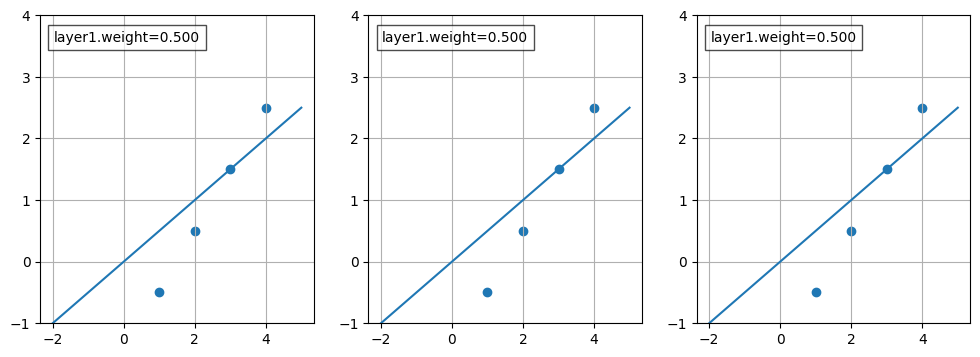

In [ ]:
class LinearModel(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.layer1 = torch.nn.Linear(1, 1, bias=False)  # Each data point has 1 input feature 
														# and each data point produces 1 output

	def forward(self, x):
		x = x.view(-1, 1)  	# convert from vector to rank-2 vector
		x = self.layer1(x)	# 'layer' expects a rank-2 vector, i.e. [[x1], [x2], ..] not [x1, x2, ...]
		x = x.flatten()   	# convert from rank-2 tensor to vector
		return x

xs_data = torch.tensor([1.,2,3,4])
ys_data = torch.tensor([-0.5, 0.5, 1.5, 2.5])

xs = torch.linspace(-2, 5, 100, dtype=torch.float32)   # dtype of nn.Linear (also default)

fig, axes = plt.subplots(1,3, figsize=(12,4))

for ax in axes:

	model = LinearModel()
	optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
	steps = 500

	for step in range(steps):
		optimizer.zero_grad()
		loss = torch.mean((model(xs_data) - ys_data)**2)
		loss.backward()
		optimizer.step()
		if step == 0 or (step+1) == steps:
			print(f"{step if step==0 else step+1:4d} Loss = {loss.item():.4f}")

	ax.scatter(xs_data, ys_data)
	ax.plot(xs.numpy(), model(xs).detach().numpy())
	ax.text(0.05, 0.95, 
		f'layer1.weight={model.layer1.weight.item():.3f}',
		transform=ax.transAxes, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
	# ax.plot(xs.numpy(), model(xs).detach().numpy(), label=r'$y=$'+f'{model.layer.weight.item():.3f}'+r'$x$')
	ax.grid()
	ax.set_ylim(-1,4)



This model can never reproduce all four points exactly since 'bias = False'. Thus the linear model *must* pass through (0,0)

### Linear data: two-parameter model

Now include bias

   0 Loss = 2.3647
5000 Loss = 0.0000
   0 Loss = 1.8229
5000 Loss = 0.0000
   0 Loss = 11.9069
5000 Loss = 0.0000


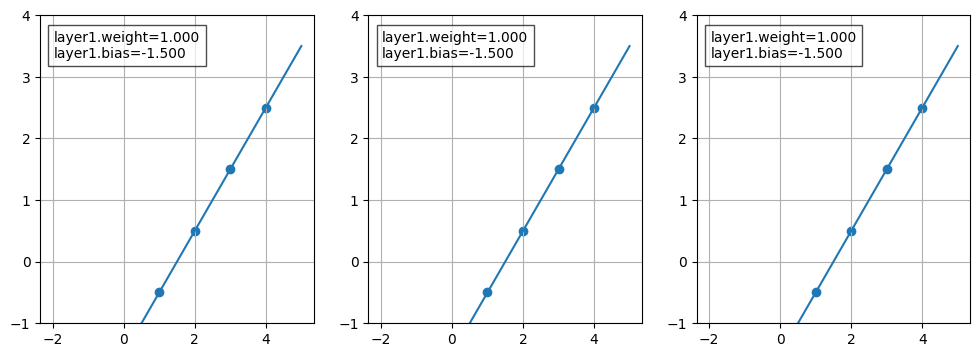

In [ ]:
class LinearModelBias(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.layer1 = torch.nn.Linear(1, 1, bias=True)  # Each data point has 1 input feature 
														# and each data point produces 1 output

	def forward(self, x):
		x = x.view(-1, 1)  	# convert from vector to rank-2 vector
		x = self.layer1(x)	# 'layer' expects a rank-2 vector, i.e. [[x1], [x2], ..] not [x1, x2, ...]
		x = x.flatten()   	# convert from rank-2 tensor to vector
		return x

xs_data = torch.tensor([1.,2,3,4])
ys_data = torch.tensor([-0.5, 0.5, 1.5, 2.5])

xs = torch.linspace(-2, 5, 100, dtype=torch.float32)   # dtype of nn.Linear (also default)

fig, axes = plt.subplots(1,3, figsize=(12,4))

for ax in axes:

	model = LinearModelBias()
	optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
	steps = 5000

	for step in range(steps):
		optimizer.zero_grad()
		loss = torch.mean((model(xs_data) - ys_data)**2)
		loss.backward()
		optimizer.step()
		if step == 0 or (step+1) == steps:
			print(f"{step if step==0 else step+1:4d} Loss = {loss.item():.4f}")

	ax.scatter(xs_data, ys_data)
	ax.plot(xs.numpy(), model(xs).detach().numpy())
	ax.text(0.05, 0.95, 
		f'layer1.weight={model.layer1.weight.item():.3f}\n' + 
		f'layer1.bias={model.layer1.bias.item():.3f}',
		transform=ax.transAxes, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
	ax.grid()
	ax.set_ylim(-1,4)



Now the bias exactly opposes the loss we converged towards in the first task.

### Non-linear data: linear model

   0 Loss = 16.4145
5000 Loss = 0.0625
   0 Loss = 13.9687
5000 Loss = 0.0625
   0 Loss = 0.1389
5000 Loss = 0.0625


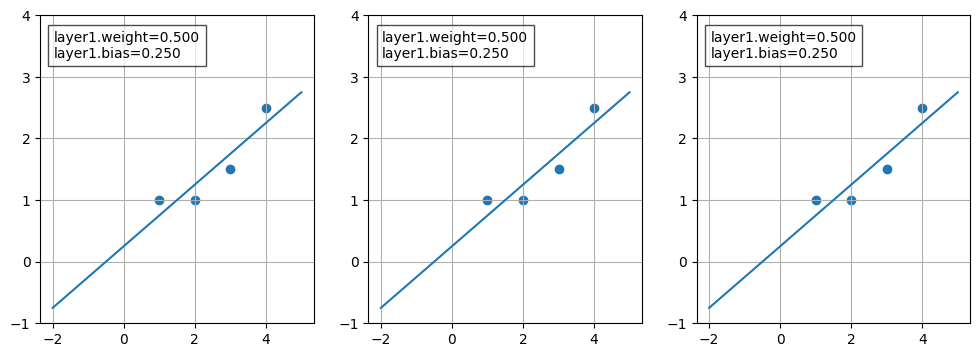

In [ ]:
xs_data = torch.tensor([1., 2, 3, 4])
ys_data = torch.tensor([1, 1, 1.5, 2.5])

xs = torch.linspace(-2, 5, 100, dtype=torch.float32)   # dtype of nn.Linear (also default)

fig, axes = plt.subplots(1,3, figsize=(12,4))

for ax in axes:

	model = LinearModelBias()
	optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
	epochs = 5000

	for epoch in range(epochs):
		optimizer.zero_grad()
		loss = torch.mean((model(xs_data) - ys_data)**2)
		loss.backward()
		optimizer.step()
		if epoch == 0 or (epoch+1) == epochs:
			print(f"{epoch if epoch==0 else epoch+1:4d} Loss = {loss.item():.4f}")

	ax.scatter(xs_data, ys_data)
	ax.plot(xs.numpy(), model(xs).detach().numpy())
	ax.text(0.05, 0.95, 
		f'layer1.weight={model.layer1.weight.item():.3f}\n' + 
		f'layer1.bias={model.layer1.bias.item():.3f}',
		transform=ax.transAxes, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
	ax.grid()
	ax.set_ylim(-1,4)



A linear model can only pass through all points if the points themselves are linearly dependent, which they are not.

### Two linear layers with SiLU between them

   0 Loss = 1.9409
5000 Loss = 0.0001
   0 Loss = 4.5559
5000 Loss = 0.0711
   0 Loss = 5.4080
5000 Loss = 0.0718


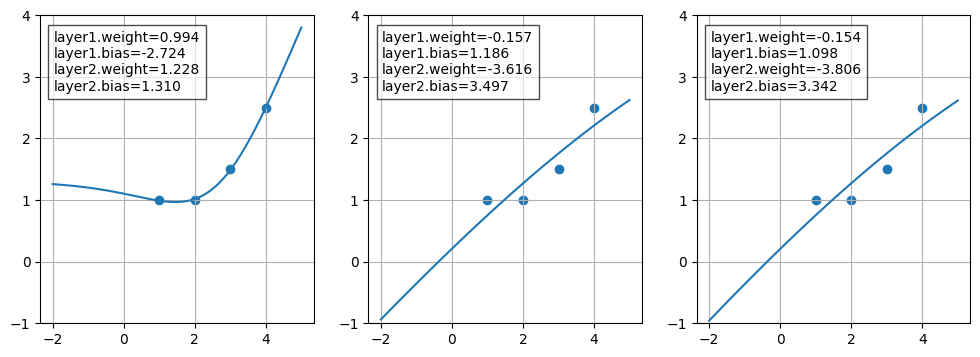

In [ ]:
class SiLUModel(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.layer1 = torch.nn.Linear(1, 1, bias=True)
		self.act1 = torch.nn.SiLU()
		self.layer2 = torch.nn.Linear(1, 1, bias=True)

	def forward(self, x):
		x = x.view(-1, 1)  	# convert from vector to rank-2 vector
		h = self.layer1(x)  # h = w1 * x + b1
		a = self.act1(h)	# a = f_silu(h)
		y = self.layer2(a)  # y = w2 * a + b2
		y = y.flatten()   	# convert from rank-2 tensor to vector
		return y

xs_data = torch.tensor([1., 2, 3, 4])
ys_data = torch.tensor([1, 1, 1.5, 2.5])

xs = torch.linspace(-2, 5, 100, dtype=torch.float32)   # dtype of nn.Linear (also default)

fig, axes = plt.subplots(1,3, figsize=(12,4))

for ax in axes:

	model = SiLUModel()
	optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
	steps = 5000

	for step in range(steps):
		optimizer.zero_grad()
		loss = torch.mean((model(xs_data) - ys_data)**2)
		loss.backward()
		optimizer.step()
		if step == 0 or (step+1) == steps:
			print(f"{step if step==0 else step+1:4d} Loss = {loss.item():.4f}")

	ax.scatter(xs_data, ys_data)
	ax.plot(xs.numpy(), model(xs).detach().numpy())
	ax.text(0.05, 0.95, 
		f'layer1.weight={model.layer1.weight.item():.3f}\n' + 
		f'layer1.bias={model.layer1.bias.item():.3f}\n' + 
		f'layer2.weight={model.layer2.weight.item():.3f}\n' + 
		f'layer2.bias={model.layer2.bias.item():.3f}',
		transform=ax.transAxes, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
	ax.grid()
	ax.set_ylim(-1,4)



These results are noticeably different. Different random initial parameters cause different minima to be explored, and the model can easily get stuck in a local minima.

### SiLU also after the output layer

   0 Loss = 2.2113
5000 Loss = 0.0002
   0 Loss = 3.3861
5000 Loss = 2.6250
   0 Loss = 0.9223
5000 Loss = 0.0535


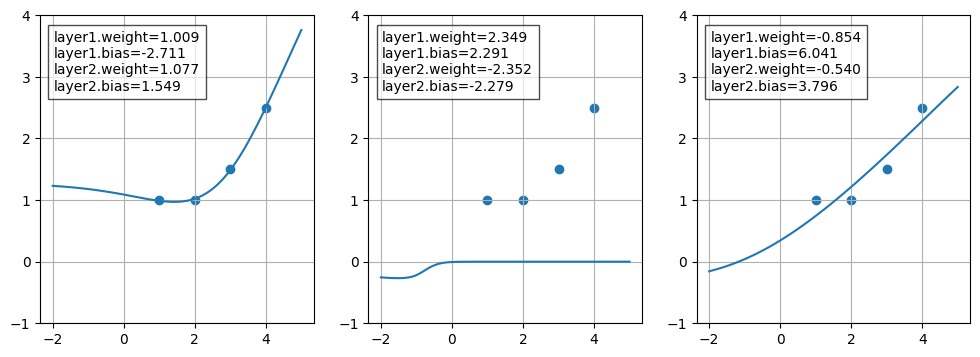

In [ ]:
class SiLUModel2(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.layer1 = torch.nn.Linear(1, 1, bias=True)
		self.silu = torch.nn.SiLU()
		self.layer2 = torch.nn.Linear(1, 1, bias=True)

	def forward(self, x):
		x = x.view(-1, 1)  	# convert from vector to rank-2 vector
		h = self.layer1(x)  # h = w1 * x + b1
		a = self.silu(h)	# a = f_silu(h)
		y = self.layer2(a)  # y = w2 * a + b2
		y = self.silu(y)	# output via activation function
		y = y.flatten()   	# convert from rank-2 tensor to vector
		return y

xs_data = torch.tensor([1., 2, 3, 4])
ys_data = torch.tensor([1, 1, 1.5, 2.5])

xs = torch.linspace(-2, 5, 100, dtype=torch.float32)   # dtype of nn.Linear (also default)

fig, axes = plt.subplots(1,3, figsize=(12,4))

for ax in axes:

	model = SiLUModel2()
	optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
	steps = 5000

	for step in range(steps):
		optimizer.zero_grad()
		loss = torch.mean((model(xs_data) - ys_data)**2)
		loss.backward()
		optimizer.step()
		if step == 0 or (step+1) == steps:
			print(f"{step if step==0 else step+1:4d} Loss = {loss.item():.4f}")

	ax.scatter(xs_data, ys_data)
	ax.plot(xs.numpy(), model(xs).detach().numpy())
	ax.text(0.05, 0.95, 
		f'layer1.weight={model.layer1.weight.item():.3f}\n' + 
		f'layer1.bias={model.layer1.bias.item():.3f}\n' + 
		f'layer2.weight={model.layer2.weight.item():.3f}\n' + 
		f'layer2.bias={model.layer2.bias.item():.3f}',
		transform=ax.transAxes, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
	ax.grid()
	ax.set_ylim(-1,4)



In regression, an activation function is usually omitted after the final linear layer because it restricts the range and shape of the possible outputs.

**Relate math to this observation?**

### A broader network
Increase the width of the hidden layer to eight neurons

   0 Loss = 1.9526
5000 Loss = 0.0000
   0 Loss = 2.8198
5000 Loss = 0.0000
   0 Loss = 1.8996
5000 Loss = 0.0000


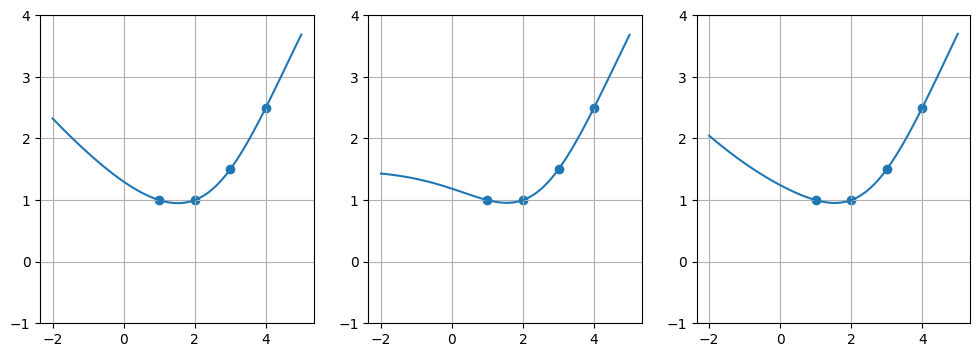

In [ ]:
class WideNN(torch.nn.Module):
	def __init__(self, hidden_dim=8):   # 8 neurons
		super().__init__()
		self.layer1 = torch.nn.Linear(1, hidden_dim, bias=True)
		self.silu = torch.nn.SiLU()
		self.layer2 = torch.nn.Linear(hidden_dim, 1, bias=True)

	def forward(self, x):
		x = x.view(-1, 1)  	# convert from vector to rank-2 vector
		h = self.layer1(x)  # h = w1 * x + b1
		a = self.silu(h)	# a = f_silu(h)
		y = self.layer2(a)  # y = w2 * a + b2
		y = y.flatten()   	# convert from rank-2 tensor to vector
		return y

xs_data = torch.tensor([1., 2, 3, 4])
ys_data = torch.tensor([1, 1, 1.5, 2.5])

xs = torch.linspace(-2, 5, 100, dtype=torch.float32)   # dtype of nn.Linear (also default)

fig, axes = plt.subplots(1,3, figsize=(12,4))

for ax in axes:

	model = WideNN()
	optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
	steps = 5000

	for step in range(steps):
		optimizer.zero_grad()
		loss = torch.mean((model(xs_data) - ys_data)**2)
		loss.backward()
		optimizer.step()
		if step == 0 or (step+1) == steps:
			print(f"{step if step==0 else step+1:4d} Loss = {loss.item():.4f}")

	ax.scatter(xs_data, ys_data)
	ax.plot(xs.numpy(), model(xs).detach().numpy())
	ax.grid()
	ax.set_ylim(-1,4)



With 8 neurons in the hidden layer, the model has greatly flexibility to capture non-linear relationships in the data. Thus we see much higher quality fits and robustness compared to just 1 hidden neuron.

# W10B Regularization

In [123]:
import torch
import matplotlib.pyplot as plt

### Noisy linear data

In [124]:
torch.manual_seed(0)
xs_train = torch.rand(32) * 6 - 2
ys_train = xs_train + 0.5 + 0.5 * torch.randn(32)

###  A model with the correct functional form

In [ ]:
class LinearModel(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.layer1 = torch.nn.Linear(1, 1, bias=True)  # Each data point has 1 input feature 
														# and each data point produces 1 output

	def forward(self, x):
		x = x.view(-1, 1)  	# convert from vector to rank-2 vector
		x = self.layer1(x)	# 'layer' expects a rank-2 vector, i.e. [[x1], [x2], ..] not [x1, x2, ...]
		x = x.flatten()   	# convert from rank-2 tensor to vector
		return x

class NN(torch.nn.Module):
	def __init__(self, hidden_dim=8):   # 8 hidden neurons
		super().__init__()
		self.silu = torch.nn.SiLU()
		self.layer1 = torch.nn.Linear(1, hidden_dim, bias=True)
		self.layer2 = torch.nn.Linear(hidden_dim, hidden_dim, bias=True)
		self.layer3 = torch.nn.Linear(hidden_dim, hidden_dim, bias=True)
		self.layer4 = torch.nn.Linear(hidden_dim, 1, bias=True)

	def forward(self, x):
		x = x.view(-1, 1)  	# convert from vector to rank-2 vector
		z1 = self.layer1(x) 	# z1 = w1 * x + b1
		h1 = self.silu(z1)		# h1 = f_silu(z1)
		z2 = self.layer2(h1)  	# z2 = w2 * h1 + b2
		h2 = self.silu(z2)		# h2 = f_silu(z2)
		z3 = self.layer3(h2) 	# z3 = w3 * h2 + b3
		h3 = self.silu(z3)		# h3 = f_silu(z3)
		y = self.layer4(h3) 	# y = w4 * h3 + b4,  dim: 8 -> 1
		y = y.flatten()   	# convert from rank-2 tensor to vector
		return y

Linear:
   0 Loss = 1.9096
1000 Loss = 0.2772
2000 Loss = 0.2772
3000 Loss = 0.2772
4000 Loss = 0.2772
5000 Loss = 0.2772


NN:
   0 Loss = 4.1001
1000 Loss = 0.2386
2000 Loss = 0.1824
3000 Loss = 0.1329
4000 Loss = 0.0877
5000 Loss = 0.0266




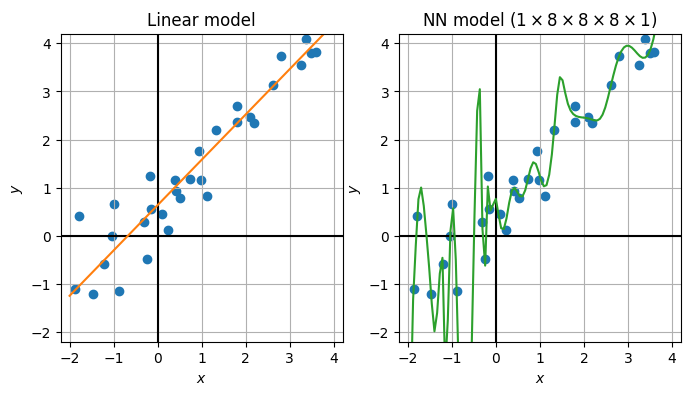

In [ ]:
xs = torch.linspace(-2, 4, 100, dtype=torch.float32)   # dtype of nn.Linear (also default)

fig, axes = plt.subplots(1,2, figsize=(8,4))

lin_model = LinearModel()
nn_model = NN()

for model, name in zip([lin_model, nn_model], ['Linear:', 'NN:']):
	print(name)
	optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
	steps = 5000

	for step in range(steps):
		optimizer.zero_grad()
		loss = torch.mean((model(xs_train) - ys_train)**2)
		loss.backward()
		optimizer.step()
		if (step+1) % 1000 == 0 or step == 0:
			print(f"{step if step==0 else step+1:4d} Loss = {loss.item():.4f}")
	print('\n')

for ax in axes:
	ax.scatter(xs_train, ys_train)
	ax.grid()
	ax.axhline(0, c='k')
	ax.axvline(0, c='k')
	ax.set_ylim(-2.2,4.2)
	ax.set_xlim(-2.2, 4.2)
	ax.set_xticks(torch.arange(-2,4+1))
	ax.set_yticks(torch.arange(-2,4+1))
	ax.set_xlabel(r'$x$', size=10)
	ax.set_ylabel(r'$y$', size=10)

axes[0].set_title('Linear model')
axes[0].plot(xs.numpy(), lin_model(xs).detach().numpy(), c='C1')
axes[0].text(0.05, 0.95, 
	f'w={lin_model.layer1.weight.item():.3f}\n' + 
	f'b={lin_model.layer1.bias.item():.3f}',
	transform=ax.transAxes, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))

axes[1].set_title(r'NN model ($1\times8\times8\times8\times1$)')
axes[1].plot(xs.numpy(), nn_model(xs).detach().numpy(), c='C2')


The linear model has greater loss, but predicts better between points than the NN-model. This obtains smaller loss but predicts wildly between points. Outside the plotted region, the linear model still predicts a linear relation, while the NN-model predicts "randomly" based on its initial conditions and the basin of minimum it ended up in. Thus a smaller training loss does not necessarily imply a "good" model.

### Regularization by weight decay

Now discourage large parameter values. This should dampen the wide predictions of the NN-model.

weight_decay= 0
	 0.020862985402345657
	 0.047016650438308716
	 0.0756845697760582
	 0.0777154266834259
weight_decay= 1e-05
	 0.029151927679777145
	 0.03818480297923088
	 0.0420982763171196
	 0.05637004226446152
weight_decay= 0.001
	 0.23535892367362976
	 0.23766282200813293
	 0.23942331969738007
	 0.2395651638507843
weight_decay= 0.1
	 0.26732462644577026
	 0.26732462644577026
	 0.26732465624809265
	 0.26732465624809265


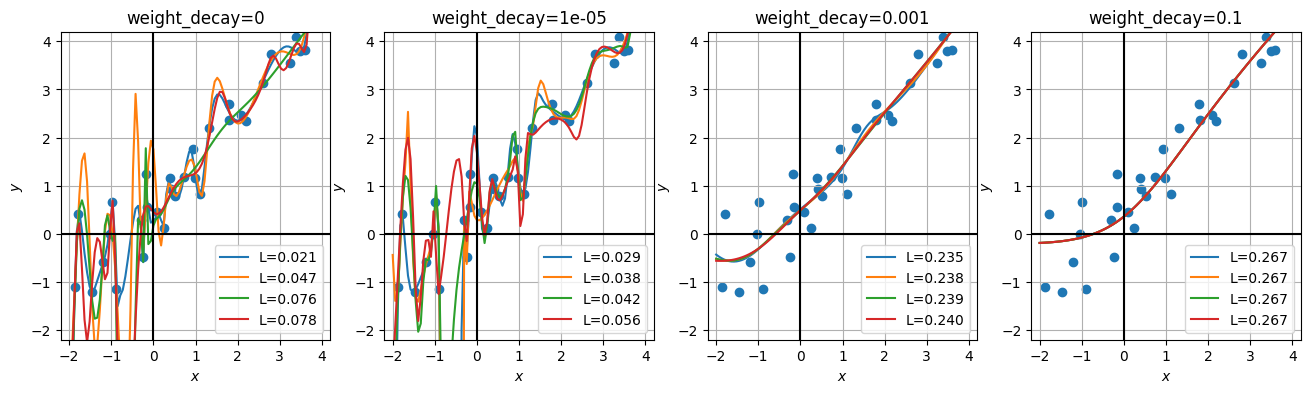

In [ ]:
weight_decay = [0, 1e-5, 1e-3, 1e-1]

xs = torch.linspace(-2, 4, 100, dtype=torch.float32)   # dtype of nn.Linear (also default)

fig, axes = plt.subplots(1, 4, figsize=(16,4))

for ax, wd in zip(axes, weight_decay):
	models = []
	for _ in range(8): # train 8 independent models
		model = NN()
		optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=wd)
		steps = 5000

		for step in range(steps):
			optimizer.zero_grad()
			loss = torch.mean((model(xs_train) - ys_train)**2)
			loss.backward()
			optimizer.step()
		models.append([model, loss])
	models.sort(key=lambda x: x[1])

	ax.set_title(f'weight_decay={wd}')
	print('weight_decay=', wd)
	for (model,loss), c in zip(models[:4], ['C1', 'C2', 'C3', 'C4']): # top 4 models with smallest loss
		print('\t', loss.item())
		ax.plot(xs.numpy(), model(xs).detach().numpy(), label=f'L={loss:.3f}')

	ax.scatter(xs_train, ys_train)
	ax.grid()
	ax.axhline(0, c='k')
	ax.axvline(0, c='k')
	ax.set_ylim(-2.2,4.2)
	ax.set_xlim(-2.2, 4.2)
	ax.set_xticks(torch.arange(-2,4+1))
	ax.set_yticks(torch.arange(-2,4+1))
	ax.set_xlabel(r'$x$', size=10)
	ax.set_ylabel(r'$y$', size=10)
	ax.legend()

*Comments?*

# W10C Pair-potential regression

In [32]:
import torch
import matplotlib.pyplot as plt

In [33]:
def pot_morse(r, r0, a, eps):
	return eps * ((1-torch.exp(-a*(r-r0)))**2 - 1)
def pot_gauss(r, rg, eps, sigma):
	return eps * torch.exp(-(r-rg)**2/sigma**2)
def f_cutoff(r, rc, lam):
	return torch.where(r<=rc, 1, torch.where(
		r < rc+lam, 1/2 * (1 + torch.cos(torch.pi * (r-rc)/lam)), 0))

(0.6, 2.075)

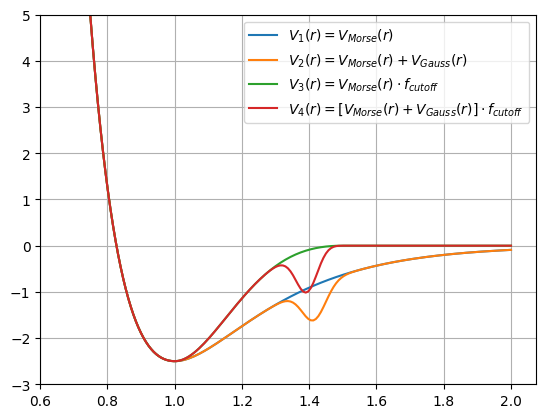

In [44]:
r0 = 1; a = 4; eps = 2.5
r = torch.linspace(0.5, 2, 200)

pot1 = pot_morse(r, r0, a, eps)
pot2 = pot_morse(r, r0, a, eps) + pot_gauss(r, rg=2**(1/2), sigma=0.05, eps=-0.75)
pot3 = f_cutoff(r, rc=1, lam=0.5) * pot_morse(r, r0, a, eps)
pot4 = f_cutoff(r, rc=1, lam=0.5) * (pot_morse(r, r0, a, eps) + pot_gauss(r, rg=2**(1/2), sigma=0.05, eps=-10))

fig, ax = plt.subplots()
ax.plot(r.numpy(), pot1.numpy(), label=r'$V_1(r)=V_{Morse}(r)$')
ax.plot(r.numpy(), pot2.numpy(), label=r'$V_2(r)=V_{Morse}(r)+V_{Gauss}(r)$')
ax.plot(r.numpy(), pot3.numpy(), label=r'$V_3(r)=V_{Morse}(r)\cdot f_{cutoff}$')
ax.plot(r.numpy(), pot4.numpy(), label=r'$V_4(r)=\left[V_{Morse}(r)+V_{Gauss}(r)\right]\cdot f_{cutoff}$')
ax.legend()
ax.grid()
ax.set_ylim(-3,5)
ax.set_xlim(0.6)

The gaussian term adds a second potential at $r_g=\sqrt{2}$. 

The $f_{cutoff}$ brings the potential up to zero at around $r=1.5$

### Noisy datasets

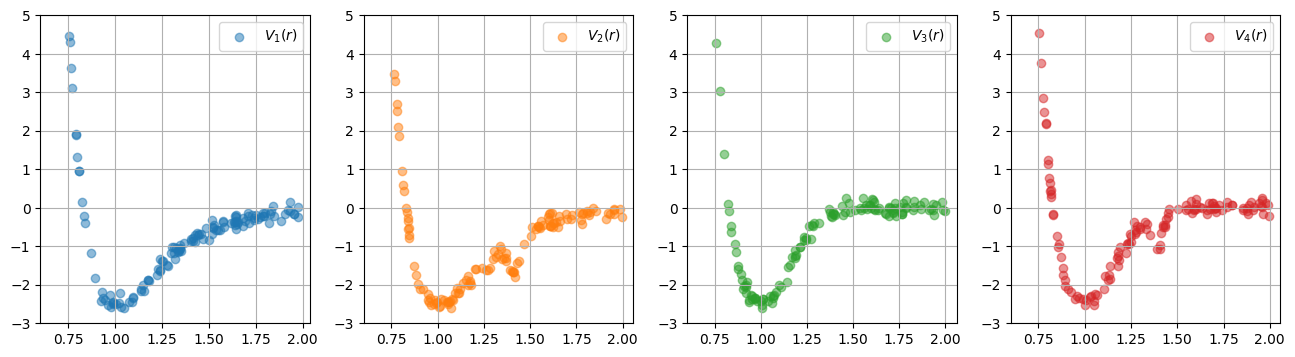

In [35]:
torch.manual_seed(2)   # to ensure consistency
r1 = torch.rand(128) * (2.0-0.75) + 0.75
r2 = torch.rand(128) * (2.0-0.75) + 0.75
r3 = torch.rand(128) * (2.0-0.75) + 0.75
r4 = torch.rand(128) * (2.0-0.75) + 0.75
noise = 0.1 * torch.randn(128)

r0 = 1; a = 4; eps = 2.5
npot1 = pot_morse(r1, r0, a, eps) + noise
npot2 = pot_morse(r2, r0, a, eps) + pot_gauss(r2, rg=2**(1/2), sigma=0.05, eps=-0.75) + noise
npot3 = f_cutoff(r3, rc=1, lam=0.5) * pot_morse(r3, r0, a, eps) + noise
npot4 = f_cutoff(r4, rc=1, lam=0.5) * (pot_morse(r4, r0, a, eps) + pot_gauss(r4, rg=2**(1/2), sigma=0.05, eps=-10)) + noise

fig, axes = plt.subplots(1,4,figsize=(16,4))
axes[0].scatter(r1.numpy(), npot1.numpy(), label=r'$V_1(r)$', c='C0', alpha=0.5)
axes[1].scatter(r2.numpy(), npot2.numpy(), label=r'$V_2(r)$', c='C1', alpha=0.5)
axes[2].scatter(r3.numpy(), npot3.numpy(), label=r'$V_3(r)$', c='C2', alpha=0.5)
axes[3].scatter(r4.numpy(), npot4.numpy(), label=r'$V_4(r)$', c='C3', alpha=0.5)
for ax in axes:
	ax.legend()
	ax.grid()
	ax.set_ylim(-3,5)
	ax.set_xlim(0.6)

We continue with the noisy data from $V_4(r)$

### Training

In [36]:
def train(model, x, y, lr=0.01, epochs=2000):
	'''Trains a model using 'Adam'. Returns a list of loss per epoch'''
	optimizer = torch.optim.Adam(model.parameters(), lr=lr)

	epoch_loss = []
	for epoch in range(epochs):
		y_pred = model(x)
		loss = torch.mean((y_pred-y)**2)
		epoch_loss.append(loss.item())

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

	return epoch_loss

In [37]:
class ParametrizedRegression(torch.nn.Module):
	def __init__(self, r0, a, eps, rg, sigma_g, eps_g, rc, lam):
		super().__init__()
		self.r0 = torch.nn.Parameter(torch.tensor(float(r0)))
		self.a = torch.nn.Parameter(torch.tensor(float(a)))
		self.eps = torch.nn.Parameter(torch.tensor(float(eps)))
		self.rg = torch.nn.Parameter(torch.tensor(float(rg)))
		self.sigma_g = torch.nn.Parameter(torch.tensor(float(sigma_g)))
		self.eps_g = torch.nn.Parameter(torch.tensor(float(eps_g)))
		self.rc = torch.nn.Parameter(torch.tensor(float(rc)))
		self.lam = torch.nn.Parameter(torch.tensor(float(lam)))

	def f_cutoff(self, r, rc, lam):
		return torch.where(r<=rc, 1, torch.where(
			r < rc+lam, 1/2 * (1 + torch.cos(torch.pi * (r-rc)/lam)), 0))

	def forward(self, r):
		term1 = self.eps_g * torch.exp(-(r-self.rg)**2/self.sigma_g**2)
		term2 = self.eps * ((1-torch.exp(-self.a*(r-self.r0)))**2 - 1)
		return self.f_cutoff(r, self.rc, self.lam) * (term1 + term2)


Model 1
r0: 1.0000, a: 4.0000, eps: 1.0000, rg: 1.4142, sigma_g: 0.2500, eps_g: -10.0000, rc: 0.5000, lam: 2.5000
r0: 0.9868, a: 4.2503, eps: 2.8577, rg: 1.5193, sigma_g: 0.0046, eps_g: -9.7663, rc: 0.3717, lam: 2.1063

Model 2
r0: 1.0000, a: 4.0000, eps: 2.5000, rg: 1.1314, sigma_g: 0.1000, eps_g: -20.0000, rc: 1.0000, lam: 1.5000
r0: 0.9966, a: 4.0609, eps: 2.5509, rg: 1.0698, sigma_g: -0.0009, eps_g: -19.8335, rc: 0.8553, lam: 0.9360

Model 3
r0: 1.0000, a: 4.0000, eps: 1.5000, rg: 1.2728, sigma_g: 0.1000, eps_g: -20.0000, rc: 1.5000, lam: 1.0000
r0: 0.9947, a: 4.1069, eps: 2.5165, rg: 1.3865, sigma_g: -0.0042, eps_g: -19.8259, rc: 0.8915, lam: 0.8603

Model 4
r0: 1.0000, a: 4.0000, eps: 2.5000, rg: 1.3435, sigma_g: 0.0750, eps_g: -20.0000, rc: 1.0000, lam: 0.5000
r0: 0.9923, a: 4.1678, eps: 2.4466, rg: 1.4340, sigma_g: -0.0588, eps_g: -19.7936, rc: 1.0436, lam: 0.4275


True values:
r0: 1.0000, a: 4.0000, eps: 2.5000, rg: 1.4142, sigma_g: 0.0500, eps_g: -10.0000, rc: 1.0000, lam: 0

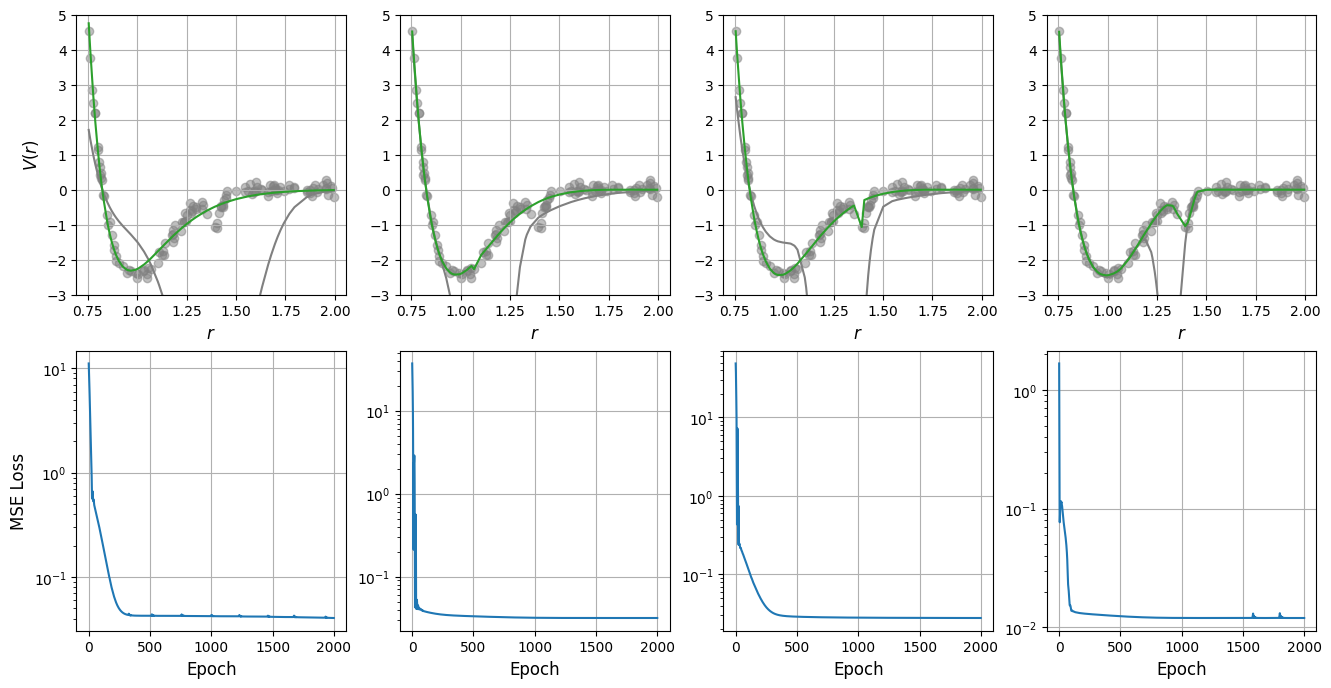

In [38]:
fig, axes = plt.subplots(2,4,figsize=(16,8))

idx = torch.argsort(r4)
xs = r4[idx]
ys = npot4[idx]

model1 = ParametrizedRegression(r0=1.0, a=4.0, eps=1.0, rc=0.5, lam=2.5, rg=2**(1/2), sigma_g=0.25, eps_g=-10)
model2 = ParametrizedRegression(r0=1.0, a=4.0, eps=2.5, rc=1.0, lam=1.5, rg=0.8*2**(1/2), sigma_g=0.10, eps_g=-20)
model3 = ParametrizedRegression(r0=1.0, a=4.0, eps=1.5, rc=1.5, lam=1.0, rg=0.9*2**(1/2), sigma_g=0.10, eps_g=-20)
model4 = ParametrizedRegression(r0=1.0, a=4.0, eps=2.5, rc=1.0, lam=0.5, rg=0.95*2**(1/2), sigma_g=0.075, eps_g=-20)
models = [model1, model2, model3, model4]
for i, model in enumerate(models):
	print('Model', i+1)
	axes[0,i].scatter(xs.numpy(), ys.numpy(), alpha=0.5, c='grey')
	axes[0,i].plot(xs.numpy(), model(xs).detach().numpy(), c='grey')
	print(", ".join(
		f"{name}: {parameter.item():.4f}"
		for name, parameter in model.named_parameters()))

	model_loss = train(model, xs, ys)
	print(", ".join(
		f"{name}: {parameter.item():.4f}"
		for name, parameter in model.named_parameters()))
	
	axes[0,i].plot(xs.numpy(), model(xs).detach().numpy(), c='C2')
	axes[1,i].plot(torch.arange(len(model_loss)), model_loss)
	axes[1,i].set_yscale('log')

	axes[0,i].set_ylim(-3,5)
	axes[1,i].set_xlabel('Epoch', size=12)
	axes[0,i].set_xlabel(r'$r$', size=12)
	print()

axes[1,0].set_ylabel('MSE Loss', size=12)
axes[0,0].set_ylabel(r'$V(r)$', size=12)
for ax in axes.flatten():
	ax.grid()

print('\nTrue values:\nr0: 1.0000, a: 4.0000, eps: 2.5000, rg: 1.4142, sigma_g: 0.0500, eps_g: -10.0000, rc: 1.0000, lam: 0.5000')

Most parameters are recovered reliably. 

$\sigma_g$ is negative, but seeing as it it squared in the potential, it has not physical meaning. 

$\varepsilon_g$ is not easily recoved when the guess is $-20$.

A small loss does not imply that all parameters have been recovered correctly. For the first three models, they find the Gaussian should be very narrow to reduce loss.

### Neural-network regression

In [ ]:
class NNRegression(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.net = torch.nn.Sequential(
			torch.nn.Linear(1, 128),
			torch.nn.SiLU(),
			torch.nn.Linear(128,128),
			torch.nn.SiLU(),
			torch.nn.Linear(128,128),
			torch.nn.SiLU(),
			torch.nn.Linear(128,1)
		)

	def forward(self, x):
		x = x.view(-1,1)
		y = self.net(x)
		return y.flatten()

Model 1

Model 2

Model 3

Model 4



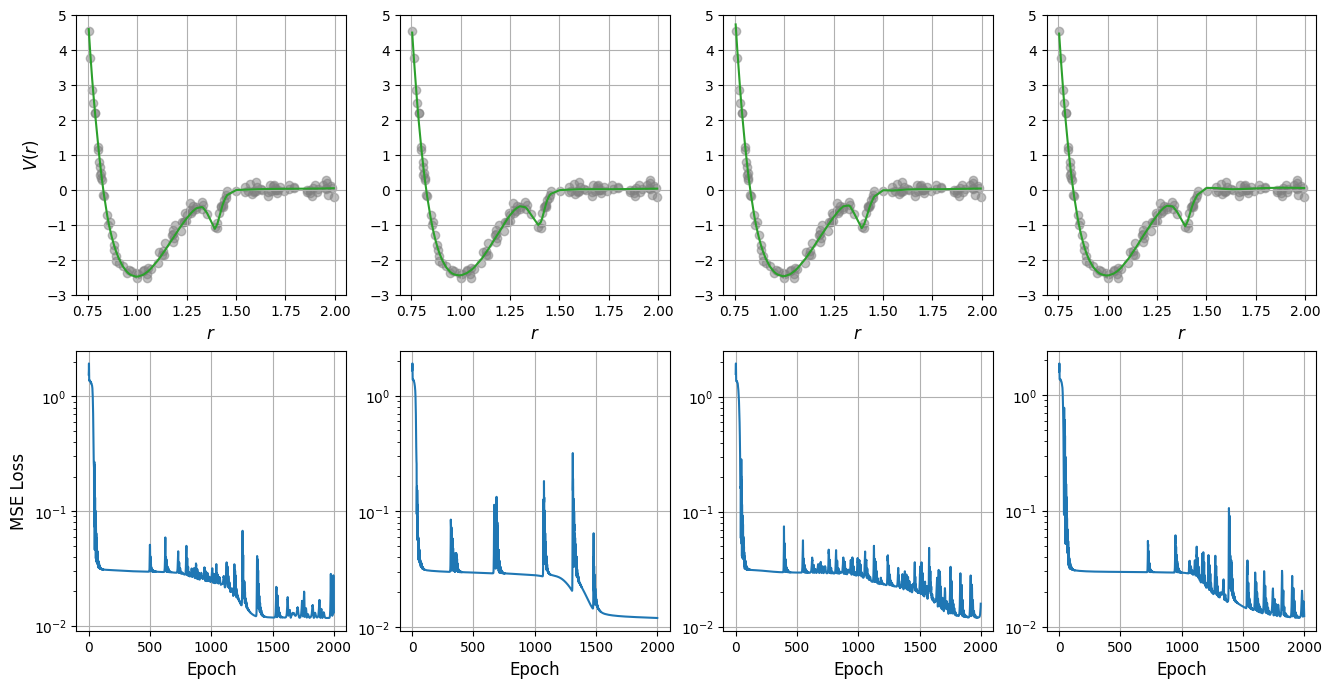

In [ ]:
torch.manual_seed(0)
nn_model1 = NNRegression()
torch.manual_seed(1)
nn_model2 = NNRegression()
torch.manual_seed(2)
nn_model3 = NNRegression()
torch.manual_seed(3)
nn_model4 = NNRegression()

fig, axes = plt.subplots(2,4,figsize=(16,8))

nn_models = [nn_model1, nn_model2, nn_model3, nn_model4]
for i, model in enumerate(nn_models):
	print('Model', i+1)
	axes[0,i].scatter(xs.numpy(), ys.numpy(), alpha=0.5, c='grey')

	model_loss = train(model, xs, ys)
	
	axes[0,i].plot(xs.numpy(), model(xs).detach().numpy(), c='C2')
	axes[1,i].plot(torch.arange(len(model_loss)), model_loss)
	axes[1,i].set_yscale('log')

	axes[0,i].set_ylim(-3,5)
	axes[1,i].set_xlabel('Epoch', size=12)
	axes[0,i].set_xlabel(r'$r$', size=12)
	print()

axes[1,0].set_ylabel('MSE Loss', size=12)
axes[0,0].set_ylabel(r'$V(r)$', size=12)
for ax in axes.flatten():
	ax.grid()

We gain much more reliable fits without requiring good initial guesses at the cost of not knowing the physical parameters of the fitted curve. This is the main trade-off.

# W10D Networks that map $R^2$ to $R^3$

In [1]:
import torch
import matplotlib.pyplot as plt

In [ ]:
x_train = torch.tensor([[0.5, 0.0], 
						[1.0, 0.0], 
						[1.5, 0.0], 
						[0.5, 0.2], 
						[1.0, 0.2], 
						[1.5, 0.7]])
theta = torch.tensor(torch.pi/6)
R = torch.tensor([[torch.cos(theta), -torch.sin(theta)],
				  [torch.sin(theta), torch.cos(theta)]])
y_train = (R @ x_train.T).T

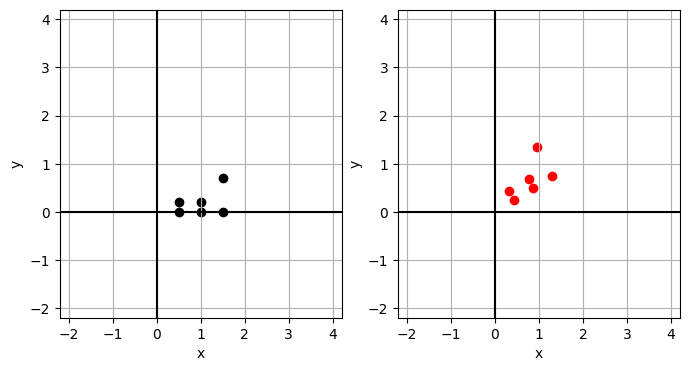

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(8,4))

for ax in axes:
	ax.set_xlim(-2.2,4.2)
	ax.set_ylim(-2.2,4.2)
	ax.set_xticks(torch.arange(-2,4+1))
	ax.set_yticks(torch.arange(-2,4+1))
	ax.set_ylabel('y')
	ax.set_xlabel('x')
	ax.axhline(0, c='k')
	ax.axvline(0, c='k')
	ax.grid()

axes[0].scatter(x_train[:,0], x_train[:,1], c='k')
axes[1].scatter(y_train[:,0], y_train[:,1], c='r')

### One linear layer without bias

layer.weight : tensor([[-0.5555,  0.0922],
        [ 0.1208, -0.3107]])
layer.weight : tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])
R=tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])


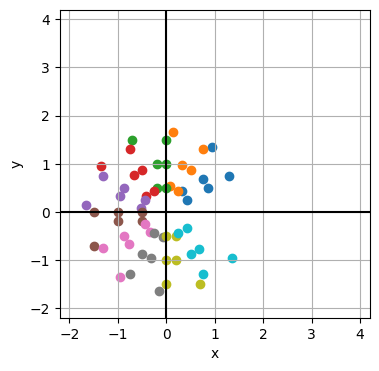

In [ ]:
class LinearModel(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.layer = torch.nn.Linear(2,2,bias=False)

	def forward(self,x):
		y = self.layer(x)
		return y

def do_one_fit(model, ax, x_train, y_train, print_loss=False):
	optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

	for _ in range(10000):
		y_pred = model(x_train)
		loss = torch.mean((y_pred-y_train)**2)
		optimizer.zero_grad()
		loss.backward()
		optimizer.step()
	if print_loss:
		print(loss)

	x = x_train
	for _ in range(10):
		x = model(x)
		with torch.no_grad():
			ax.scatter(x[:,0], x[:,1])
	ax.set_xlim(-2.2,4.2)
	ax.set_ylim(-2.2,4.2)
	ax.set_xticks(torch.arange(-2,4+1))
	ax.set_yticks(torch.arange(-2,4+1))
	ax.set_ylabel('y')
	ax.set_xlabel('x')
	ax.axhline(0, c='k')
	ax.axvline(0, c='k')
	ax.grid()


fig, ax = plt.subplots(1,1,figsize=(4,4))

model = LinearModel()
for name, parameter in model.named_parameters():
	print(name, ':', parameter.data)

do_one_fit(model=model, ax=ax, x_train=x_train, y_train=y_train)
for name, parameter in model.named_parameters():
	print(name, ':', parameter.data)
print(f'{R=}')

Rotating a point with the rotation matrix should trace out a circle, which is what we see in the figure.

### One linear layer with bias

layer.weight : tensor([[ 0.2108, -0.0823],
        [-0.6964, -0.3716]])
layer.bias : tensor([-0.5835,  0.3486])
layer.weight : tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])
layer.bias : tensor([7.5948e-07, 5.0651e-07])
R=tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])


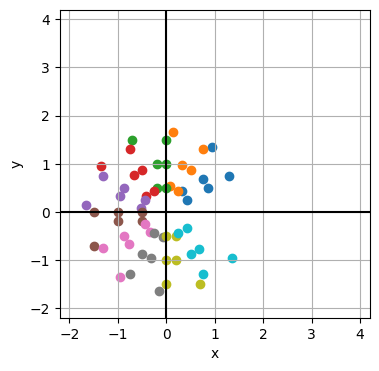

In [ ]:
class LinearBiasModel(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.layer = torch.nn.Linear(2,2,bias=True)

	def forward(self,x):
		y = self.layer(x)
		return y

fig, ax = plt.subplots(1,1,figsize=(4,4))

model = LinearBiasModel()
for name, parameter in model.named_parameters():
	print(name, ':', parameter.data)

do_one_fit(model=model, ax=ax, x_train=x_train, y_train=y_train)
for name, parameter in model.named_parameters():
	print(name, ':', parameter.data)
print(f'{R=}')

Here we do a linear transformation $y=Wx$ followed by the addition of bias $b$, which is also called an *affine transformation*.

The optimal bias $b=0$ for a rotation around origin, since the points don't need to be shifted in any direction.

### Two consecutive linear layers with bias

W2@W1 = 
tensor([[ 0.7133, -0.8100],
        [ 0.5463,  1.1799]]) 
@ tensor([[1.0084, 0.2685],
        [0.0910, 0.7964]]) 
= tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])
W2@W1 = 
tensor([[-0.3780, -0.8111],
        [-1.0679,  0.9311]]) 
@ tensor([[-0.2236, -0.7318],
        [-1.1415, -0.0642]]) 
= tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])
W2@W1 = 
tensor([[-0.9033, -0.1823],
        [ 0.3128,  2.1231]]) 
@ tensor([[-1.0723, -0.3276],
        [-0.4249,  0.3714]]) 
= tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])

R=tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])


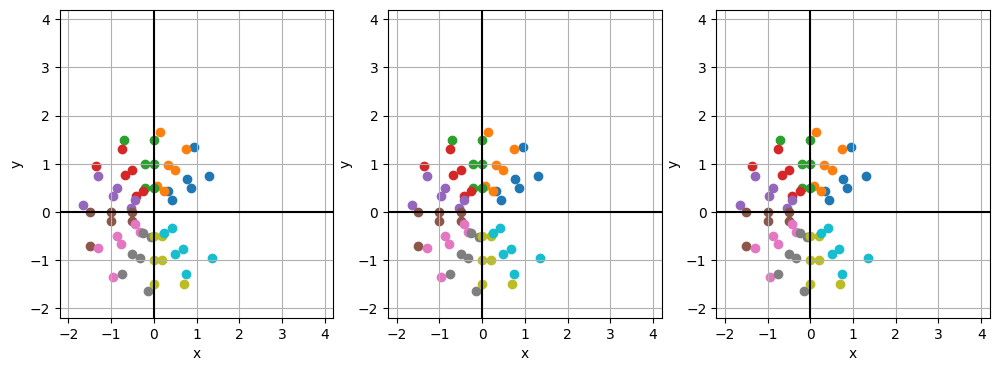

In [ ]:
class ConsecutiveLinearModel(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.layer1 = torch.nn.Linear(2,2)
		self.layer2 = torch.nn.Linear(2,2)

	def forward(self,x):
		h = self.layer1(x)
		y = self.layer2(h)
		return y

fig, axes = plt.subplots(1,3,figsize=(12,4))

for ax in axes:
	model = ConsecutiveLinearModel()
	do_one_fit(model=model, ax=ax, x_train=x_train, y_train=y_train)

	print('W2@W1 = ')
	print(model.layer1.weight.data, '\n@', model.layer2.weight.data, '\n=', model.layer2.weight.data@model.layer1.weight.data)
print(f'\n{R=}')

Without an activation function between layers we have:

$h=W_1x+b_1$

$y=W_2h+b_2=W_2(W_1x+b_1)+b_2=W_2W_1x + (W_2b_1 + b_2)$

which is on the same form as $h$. Thus two layers with no activation function between them is the same as one layer, and computing the matrixproduct reveals the predicted weight that is approximately $R$. The two layers are effectively just one affine transformation, not two, therefore the individual layer parameters are not uniquely defined.

Different initialization give different optimal $W_1$ and $W_2$, even though the overall mapping should be the same.

### Rotation around a displaced point

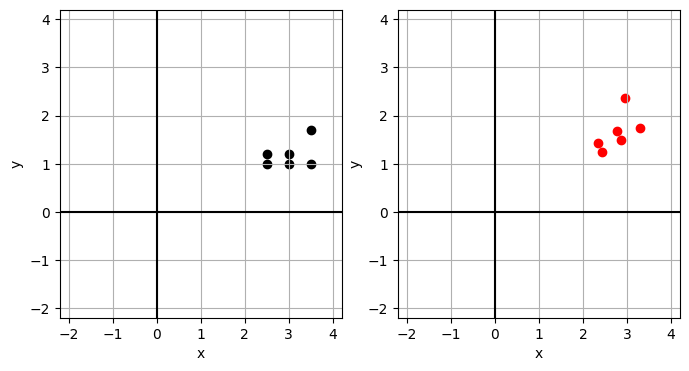

In [ ]:
x0 = torch.tensor([2.0,1.0])
xt_train = x_train + x0
yt_train = x0 + (R @ (xt_train-x0).T).T

fig, axes = plt.subplots(1,2,figsize=(8,4))

for ax in axes:
	ax.set_xlim(-2.2,4.2)
	ax.set_ylim(-2.2,4.2)
	ax.set_xticks(torch.arange(-2,4+1))
	ax.set_yticks(torch.arange(-2,4+1))
	ax.set_ylabel('y')
	ax.set_xlabel('x')
	ax.axhline(0, c='k')
	ax.axvline(0, c='k')
	ax.grid()

axes[0].scatter(xt_train[:,0], xt_train[:,1], c='k')
axes[1].scatter(yt_train[:,0], yt_train[:,1], c='r')

### One linear layer without bias

layer.weight : tensor([[ 1.0738, -0.3887],
        [ 0.2657,  0.7405]])
R=tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])


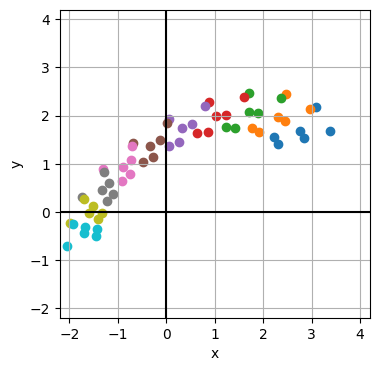

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(4,4))

model = LinearModel()

do_one_fit(model=model, ax=ax, x_train=xt_train, y_train=yt_train)
for name, parameter in model.named_parameters():
	print(name, ':', parameter.data)
print(f'{R=}')

Without bias, the linear model $y=Wx$ cannot describe a rotation around any other point than origin.

Consider that $x=2, y=0$ at a point in the rotation. Then the linear relation is only fulfilled for $w=0$, which is clearly not true for any instance of the rotation matrix. Here a bias must be introduced to shift the prediction.

### One linear layer with bias

tensor(1.2465e-10, grad_fn=<MeanBackward0>)
layer.weight : tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])
layer.bias : tensor([ 0.7679, -0.8660])
R=tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])
b=tensor([[ 0.7679],
        [-0.8660]])


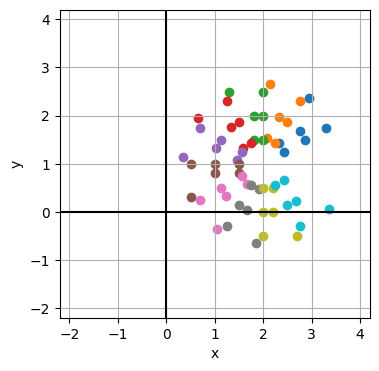

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(4,4))

model = LinearBiasModel()

do_one_fit(model=model, ax=ax, x_train=xt_train, y_train=yt_train, print_loss=True)
for name, parameter in model.named_parameters():
	print(name, ':', parameter.data)
print(f'{R=}')
I = torch.eye(2)
bias = (I-R) @ x0.view(-1,1)
print(f'b={bias}')

It sometimes gets the solution exactly, but often not. This may be because of too few training data or too few epochs.

### Two consecutive linear layers with bias

W2@W1 = 
tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])
W2@b1 + b2 = 
tensor([ 0.7680, -0.8660]) 

W2@W1 = 
tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])
W2@b1 + b2 = 
tensor([ 0.7679, -0.8660]) 

W2@W1 = 
tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])
W2@b1 + b2 = 
tensor([ 0.7680, -0.8660]) 

R=tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])
b=tensor([[ 0.7679],
        [-0.8660]])


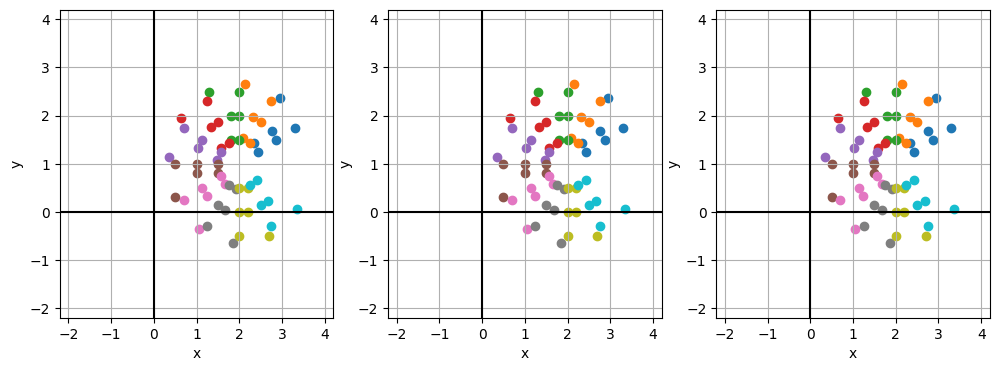

In [ ]:
fig, axes = plt.subplots(1,3,figsize=(12,4))

for ax in axes:
	model = ConsecutiveLinearModel()
	do_one_fit(model=model, ax=ax, x_train=xt_train, y_train=yt_train)

	print('W2@W1 = ')
	print(model.layer2.weight.data@model.layer1.weight.data)
	print('W2@b1 + b2 = ')
	print(model.layer2.weight.data@model.layer1.bias.data + model.layer2.bias.data, '\n')
print(f'{R=}')
print(f'b={bias}')

*How come this is so much more consistent, although it is mathematically just one affine transformation?*

If we keep training on the same model in the task of just one layer, we get very low loss. In this exercise, more training is not needed. This may indicate that a bad initial guess on one layer can yield high loss, while the likelihood of two layers having bad initial guess is much lower, and thus is more consistent.

### Two consecutive layers without bias

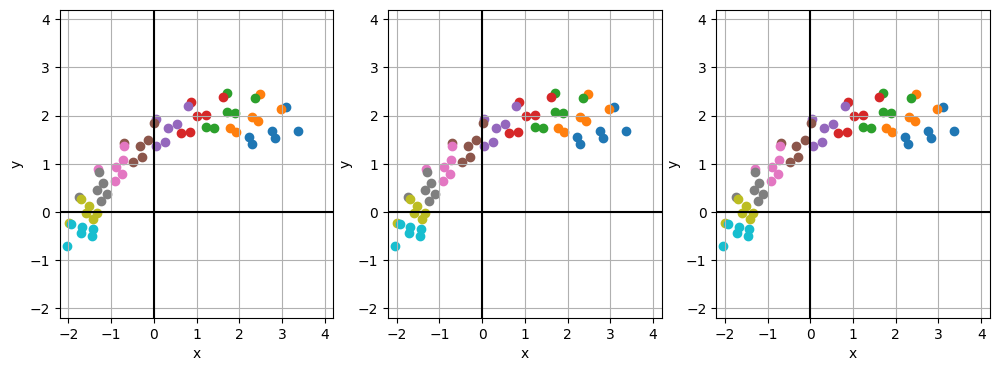

In [ ]:
class ConsecutiveLinearNoBiasModel(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.layer1 = torch.nn.Linear(2,2, bias=False)
		self.layer2 = torch.nn.Linear(2,2, bias=False)

	def forward(self,x):
		h = self.layer1(x)
		y = self.layer2(h)
		return y

fig, axes = plt.subplots(1,3,figsize=(12,4))

for ax in axes:
	model = ConsecutiveLinearNoBiasModel()
	do_one_fit(model=model, ax=ax, x_train=xt_train, y_train=yt_train)

$h = W_1x$

$y = W_2h = W_2W_1x$

Thus this is does not create the translation required for a rotation around $x_0$

### A wider and deeper linear network

layer1.weight : tensor([[ 0.2586, -0.7080],
        [-0.1996, -0.1790],
        [-0.4820,  0.3055],
        [-0.5463, -0.1243],
        [ 0.3838, -0.3556],
        [-0.7546,  0.5275],
        [ 0.4239,  0.7415],
        [-0.0145,  0.6950]])
layer1.bias : tensor([ 0.4456,  0.2073, -0.1783,  0.2834,  0.5104, -0.3834, -0.2878,  0.6288])
layer2.weight : tensor([[-0.0741,  0.4364,  0.1794,  0.4021, -0.2900,  0.1470, -0.3332, -0.1293],
        [ 0.1397,  0.0468, -0.0826, -0.4770,  0.3296, -0.2915,  0.3276,  0.2052],
        [-0.4202, -0.1770,  0.0046,  0.1455,  0.0447, -0.0551, -0.1359, -0.2714],
        [ 0.2374,  0.0202, -0.1049,  0.1078, -0.0722, -0.3423, -0.0166,  0.1698],
        [ 0.1114, -0.1067,  0.0475,  0.0486,  0.3015,  0.2206, -0.1885,  0.2951],
        [-0.2382,  0.4154,  0.2020,  0.4823,  0.0213,  0.2075,  0.2479, -0.1816],
        [ 0.2330, -0.3180, -0.4543, -0.0789,  0.2331,  0.1058,  0.4538,  0.1596],
        [ 0.8178, -0.2543, -0.0317,  0.1407,  0.4661, -0.3010, -0.2869, -0

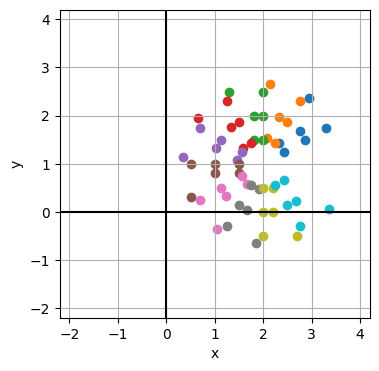

In [ ]:
class WiderDeeperLinearModel(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.layer1 = torch.nn.Linear(2,8)
		self.layer2 = torch.nn.Linear(8,8)
		self.layer3 = torch.nn.Linear(8,2)

	def forward(self,x):
		h1 = self.layer1(x)
		h2 = self.layer2(h1)
		y = self.layer3(h2)
		return y

fig, ax = plt.subplots(1,1,figsize=(4,4))

model = WiderDeeperLinearModel()
do_one_fit(model=model, ax=ax, x_train=xt_train, y_train=yt_train)
for name, parameter in model.named_parameters():
	print(name, ':', parameter.data)

*Comments?*

*Bjørk har lavet en fejl i sin opgave*

# W10E Mapping $R^2 \rightarrow R^3$

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

### Plot

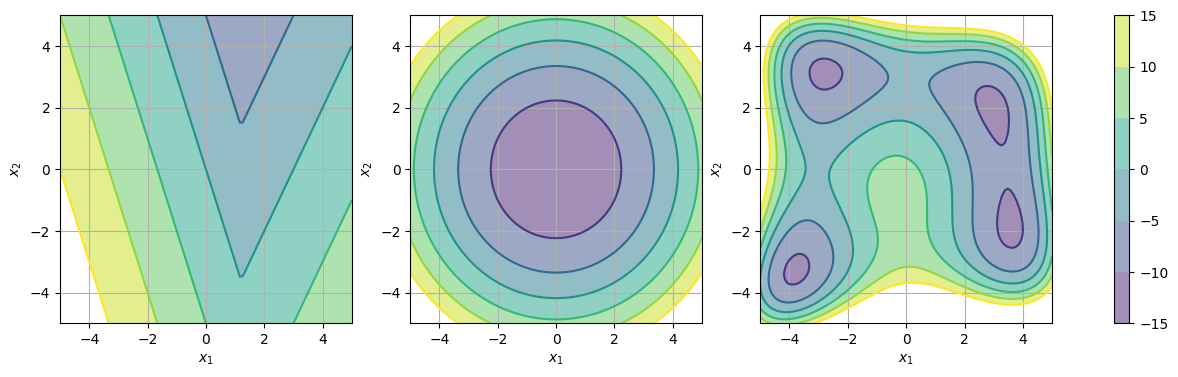

In [2]:
f1 = lambda x1 , x2: np.maximum(2*x1 - x2 - 6, -3*x1 - x2)
f2 = lambda x1 , x2: 0.8 * (x1**2 + x2**2) - 14
f3 = lambda x1 , x2: 0.1 * ((x1**2 + x2 - 11)**2 + (x1 + x2**2 - 7)**2) - 11

fig, axes = plt.subplots(1,3,figsize=(16,4))

for f, ax in zip([f1, f2, f3], axes):
	vals = np.linspace(-5,5,100)
	x1, x2 = np.meshgrid(vals, vals)
	y = f(x1, x2)


	levels = np.arange(-15, 15+5, 5)
	ax.contour(x1, x2, y, levels=levels)
	color_map = ax.contourf(x1, x2, y, levels=levels, alpha=0.5)
	ax.set(xlabel='$x_1$', ylabel='$x_2$')
	ax.grid()

fig.colorbar(color_map, ax=axes)

### Training data

In [13]:
N = 200
x = 8*np.random.rand(N, 2)-4
y1 = f1(*x.T)
y2 = f2(*x.T)
y3 = f3(*x.T)
y = np.array([y1, y2, y3]).T
X = torch.tensor(x, dtype=torch.float32)
Y = torch.tensor(y, dtype=torch.float32)

### Rudimentary Fit

In [16]:
class RudimentaryFit(torch.nn.Module):
	def __init__(self, width=4, depth=3):
		'''
		"depth" is the number of trainable affine transformations, 
		including the output transformation
		'''
		super().__init__()
		
		layers = [torch.nn.Linear(2, width),
				  torch.nn.SiLU(),
				  ]
		
		for _ in range(depth-2):
			layers.extend([torch.nn.Linear(width, width),
						   torch.nn.SiLU(),
						   ])
			
		layers.extend([torch.nn.Linear(width, 3)])
		
		self.net = torch.nn.Sequential(*layers)

	def forward(self, x):
		return self.net(x)

def train(model, x_train, y_train, lr=0.01, epochs=2000, weight_decay=0):
	'''Trains a model using "Adam".'''
	optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

	for epoch in range(epochs):
		y_pred = model(x_train)
		loss = torch.mean((y_pred-y_train)**2)
		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

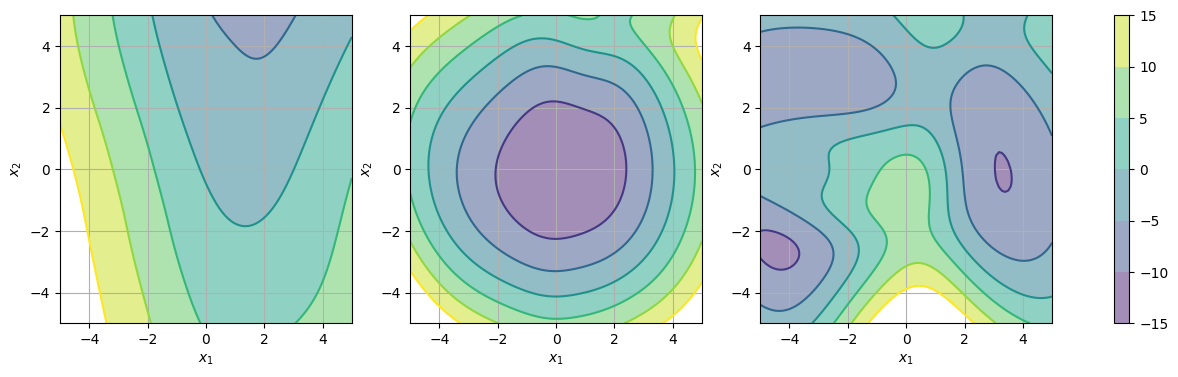

In [20]:
def do_fit(lr, epochs, width, depth, weight_decay=0):
	model = RudimentaryFit(width=width, depth=depth)
	train(model, X, Y, lr=lr, epochs=epochs, weight_decay=weight_decay)

	vals = torch.linspace(-5, 5, 100)
	x1, x2 = torch.meshgrid(vals, vals, indexing='xy')
	xs = torch.stack([x1.flatten(), x2.flatten()], dim=1)
	with torch.no_grad():
		pred = model(xs)

	fig, axes = plt.subplots(1,3,figsize=(16,4))

	for i, ax in enumerate(axes):
		# each i relates to a function, so for each function we collect the predictions:
		# also, we must reshape y to have 100x100 (meshgrid) and not just 10.000 points.
		y = pred[:, i].reshape(100, 100).numpy()
		levels = np.arange(-15, 15+5, 5)
		ax.contour(x1, x2, y, levels=levels)
		color_map = ax.contourf(x1, x2, y, levels=levels, alpha=0.5)
		ax.set(xlabel='$x_1$', ylabel='$x_2$')
		ax.grid()

	fig.colorbar(color_map, ax=axes)

do_fit(lr=0.01, epochs=10_000, width=4, depth=3)

### Better fit

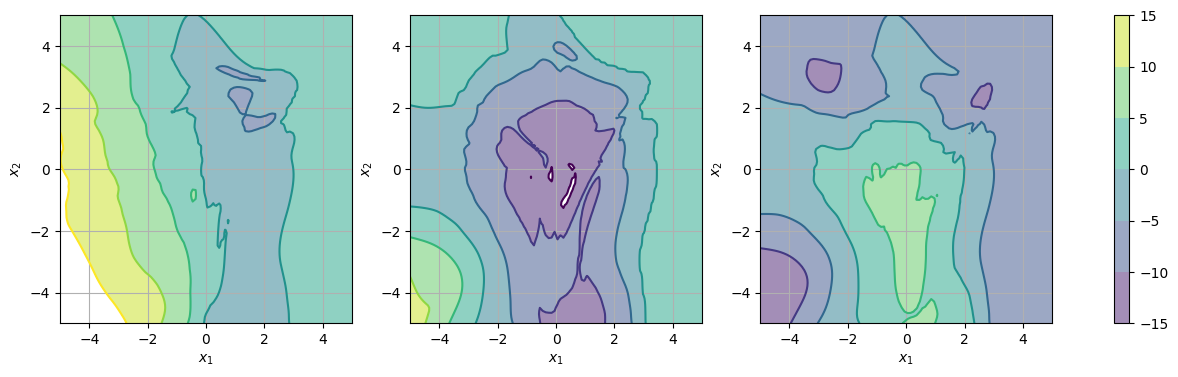

In [23]:
do_fit(lr=0.01, epochs=10_000, width=128, depth=6)

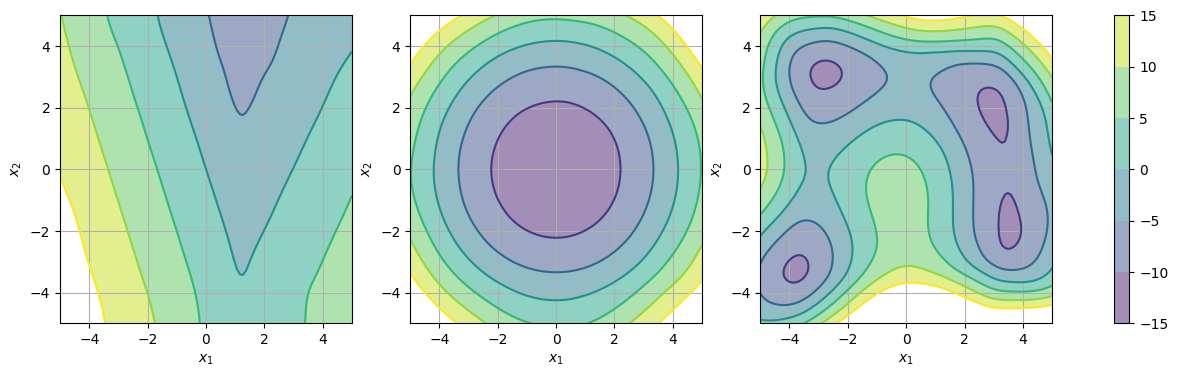

In [24]:
do_fit(lr=0.01, epochs=10_000, width=128, depth=3)

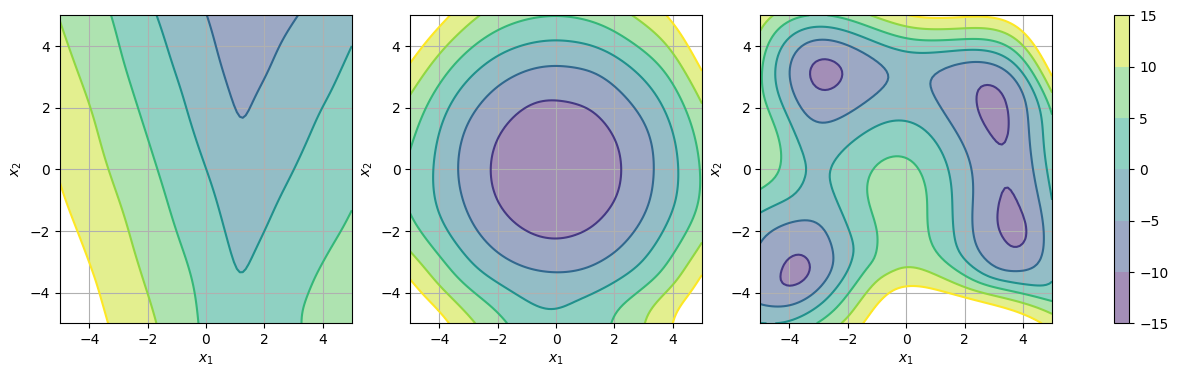

In [27]:
do_fit(lr=0.01, epochs=10_000, width=16, depth=3)

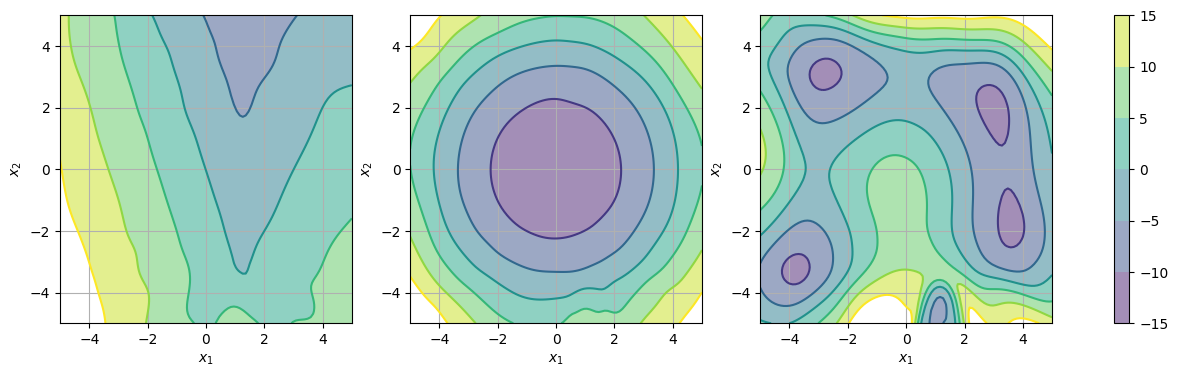

In [29]:
do_fit(lr=0.01, epochs=10_000, width=16, depth=8)

It seems that a large width (128) and depth (6) leads to very distorted results, likely due to overfitting. It finds pattern in the data that is not actually there and infers meaning from it.

Too many layers (depth) seems to give weird artifacts, also overfitting.

A subtle depth of 3 and a wider network seems appropriate.

### How about using weight decay (regularization)?

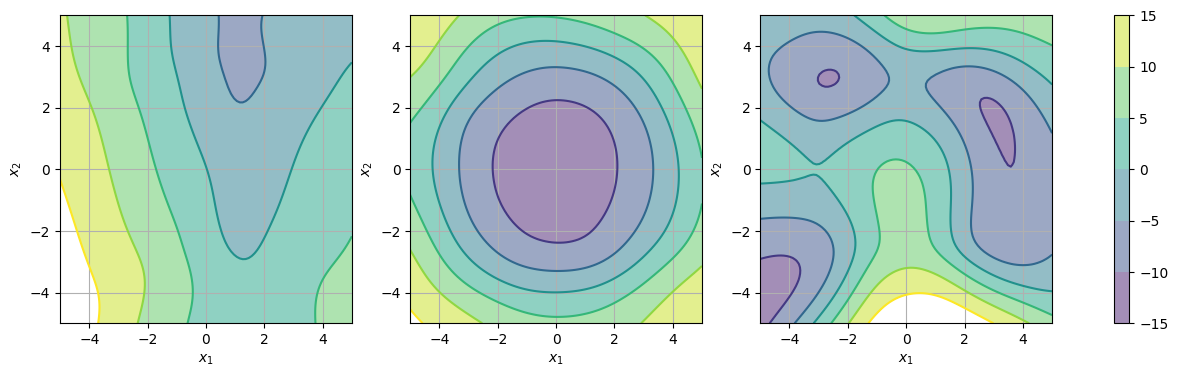

In [30]:
do_fit(lr=0.01, epochs=10_000, width=128, depth=6, weight_decay=0.1)

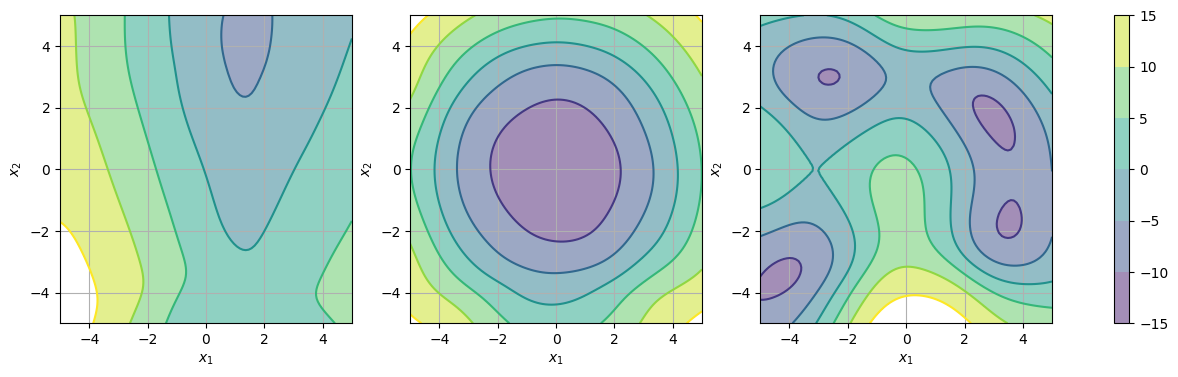

In [31]:
do_fit(lr=0.01, epochs=10_000, width=32, depth=6, weight_decay=0.1)

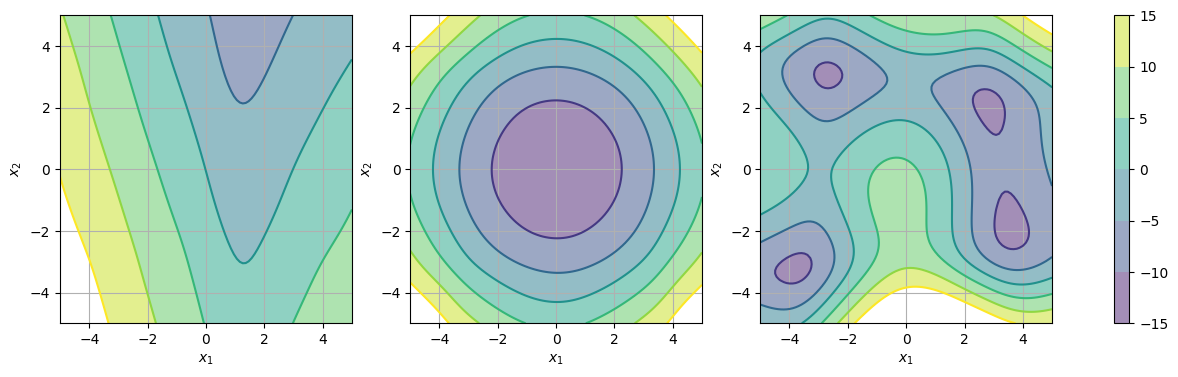

In [34]:
do_fit(lr=0.01, epochs=10_000, width=128, depth=3, weight_decay=0.01)

Weight decay definately supresses the blurry effect of overfitting, but it does not make the fit perfect.

# W10F Collisions with an equivariant neural network

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt

### Collision kinematics

### Datasets

In [3]:
# seed = torch.seed()
# print(f"Random seed used: {seed}")
# torch.manual_seed(1727405438023100)
torch.manual_seed(5)

N = 1000
r1 = 2*torch.rand(N,2)-1
theta = 2*torch.pi*torch.rand(N)
radius = 0.5
r2 = r1 + 2*radius * torch.stack([torch.cos(theta), torch.sin(theta)], dim=1)

u = torch.rand(N, 2) 
v1 = torch.where(u<0.5, 0.3+u, -0.3-u)  # to ensure velocities are not zero
# The vector going from r2 to r1 (r = r1 - r2) describes a vector between the disks
# For the particles to collide, we must look at the velocity vector from v2 to v1 (v = v1 - v2)
# If v is parallel to r, no collision will occur. If they are antiparallel (or some component is), they will collide.
# Thus we look at r dot v being negative.

v2 = []
for r1i, r2i, v1i in zip(r1, r2, v1):
	u = torch.rand(1, 2)
	v2i_candidate = torch.where(u<0.5, 0.3+u, -0.3-u)
	while (r1i-r2i) @ (v1i - v2i_candidate).T >= 0:
		u = torch.rand(1, 2)
		v2i_candidate = torch.where(u<0.5, 0.3+u, -0.3-u)
	v2.append(v2i_candidate.squeeze(0))
v2 = torch.stack(v2)

d = r1 - r2
# w1 = v1 - ((v1-v2)@d.T)/(d@d.T)@d
# w2 = v2 + ((v1-v2)@d.T)/(d@d.T)@d

v = v1 - v2

factor = (v * d).sum(dim=1, keepdim=True) / (d * d).sum(dim=1, keepdim=True)

w1 = v1 - factor * d
w2 = v2 + factor * d

momentum_before = v1[0] + v2[0]
momentum_after = w1[0] + w2[0]

print(f'{momentum_before=}')
print(f'{momentum_after=}')

X = torch.stack([r1[:,0], r1[:,1], r2[:,0], r2[:,1], v1[:,0], v1[:,1], v2[:,0], v2[:,1]], dim=1)
Y = torch.stack([w1[:,0], w1[:,1], w2[:,0], w2[:,1]], dim=1)


momentum_before=tensor([-0.1922, -2.3119])
momentum_after=tensor([-0.1922, -2.3119])


C:\Users\emilk\AppData\Local\Temp\ipykernel_13048\2993281473.py:24: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4323.)
  p1 = (R @ p1.T).T


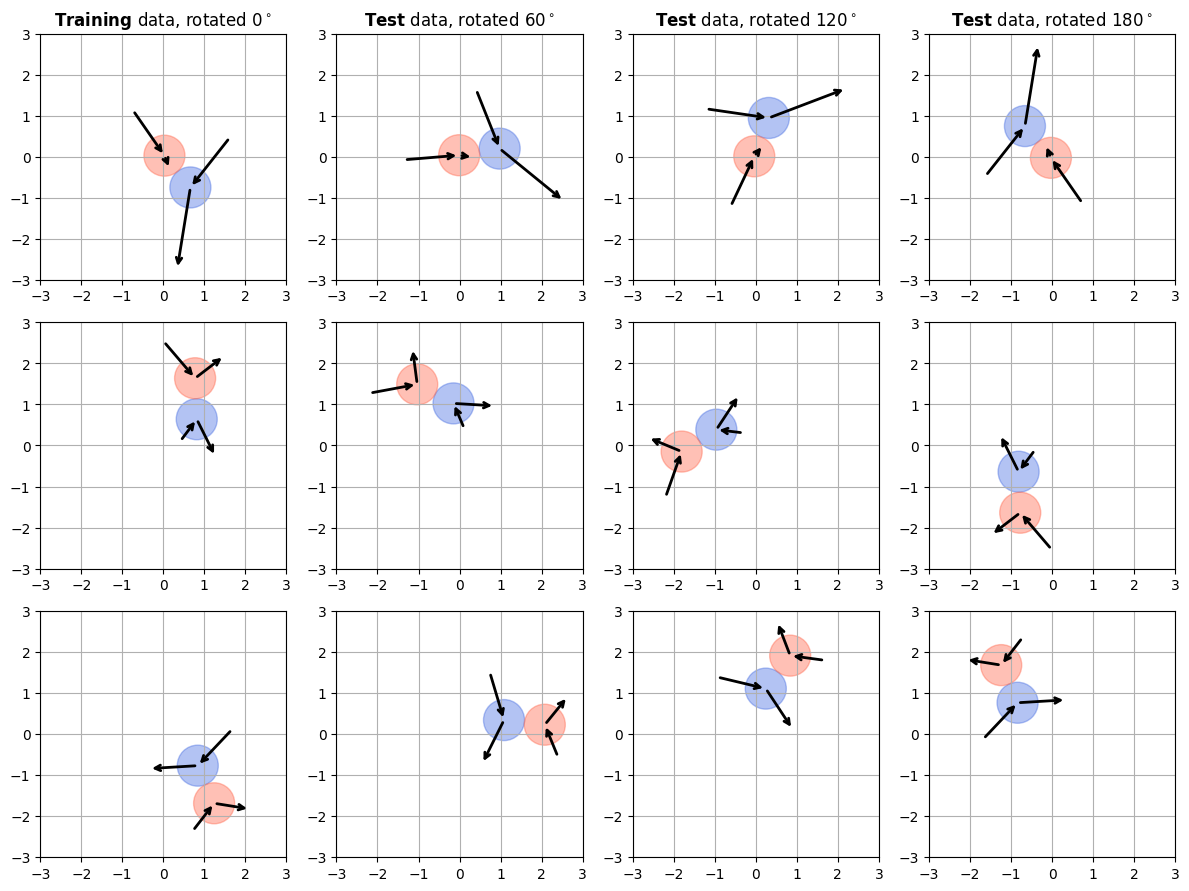

In [51]:
from matplotlib.patches import Circle

theta = torch.tensor(torch.pi/3)   # 60 degrees
R = torch.tensor([[torch.cos(theta), -torch.sin(theta)],
			  [torch.sin(theta), torch.cos(theta)]])


def plot_data(fig, axes):
	with torch.no_grad():
		for i, row in enumerate(axes):
			for j, ax in enumerate(row):
				if j == 0:
					# Extract positions and velocities
					p1 = r1[i]
					p2 = r2[i]

					vel1 = v1[i]
					vel2 = v2[i]

					post1 = w1[i] 
					post2 = w2[i]

				else:
					p1 = (R @ p1.T).T
					p2 = (R @ p2.T).T

					vel1 = (R @ vel1.T).T
					vel2 = (R @ vel2.T).T

					post1 = (R @ post1.T).T
					post2 = (R @ post2.T).T

				# Draw disks
				ax.add_patch(Circle(p1, radius, color='royalblue', alpha=0.4))
				ax.add_patch(Circle(p2, radius, color='tomato', alpha=0.4))

				# Incoming velocities (dashed arrows ending at disk centres)
				ax.annotate('', xy=p1, xytext=p1 - vel1, 
							arrowprops=dict(arrowstyle='->', color='k', linestyle='solid', lw=2))
							# arrowprops=dict(arrowstyle='->', color='blue', linestyle='dashed', lw=2))

				ax.annotate('', xy=p2, xytext=p2 - vel2, 
							arrowprops=dict(arrowstyle='->', color='k', linestyle='solid', lw=2))
							# arrowprops=dict(arrowstyle='->', color='red', linestyle='dashed', lw=2))

				# Outgoing velocities (solid arrows starting at disk centres)
				ax.annotate('', xy=p1 + post1, xytext=p1,
							arrowprops=dict(arrowstyle='->', color='k', linestyle='solid', lw=2))
							# arrowprops=dict(arrowstyle='->', color='blue', lw=2))

				ax.annotate('', xy=p2 + post2, xytext=p2,
							arrowprops=dict(arrowstyle='->', color='k', linestyle='solid', lw=2))
							# arrowprops=dict(arrowstyle='->', color='red', lw=2))

				# Formatting
				if i==0 and j == 0:
					ax.set_title(r'$\mathbf{Training}$ data, rotated $0^\circ$')
				elif i==0 and j != 0:
					ax.set_title(r'$\mathbf{Test}$ data, rotated '+f'{j*60}'+r'$^\circ$')
				ax.set_aspect('equal')
				ax.grid()
				ax.set_xlim(-3, 3)
				ax.set_ylim(-3, 3)
				ax.set_xticks(np.arange(-3,3+1))

		fig.tight_layout()

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
plot_data(fig, axes)

A non-equivariant neural network

In [52]:
class NN(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.net = torch.nn.Sequential(
			torch.nn.Linear(8, 64),
			torch.nn.SiLU(),
			torch.nn.Linear(64,64),
			torch.nn.SiLU(),
			torch.nn.Linear(64,4),
		)

	def forward(self, x):
		return self.net(x)

def train(model, x_train, y_train, lr=0.001, epochs=1000):
	'''Trains a model using "Adam".'''
	optimizer = torch.optim.Adam(model.parameters(), lr=lr)

	for epoch in range(epochs):
		y_pred = model(x_train)
		loss = torch.mean((y_pred-y_train)**2)
		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

Training on just 100 collisions:

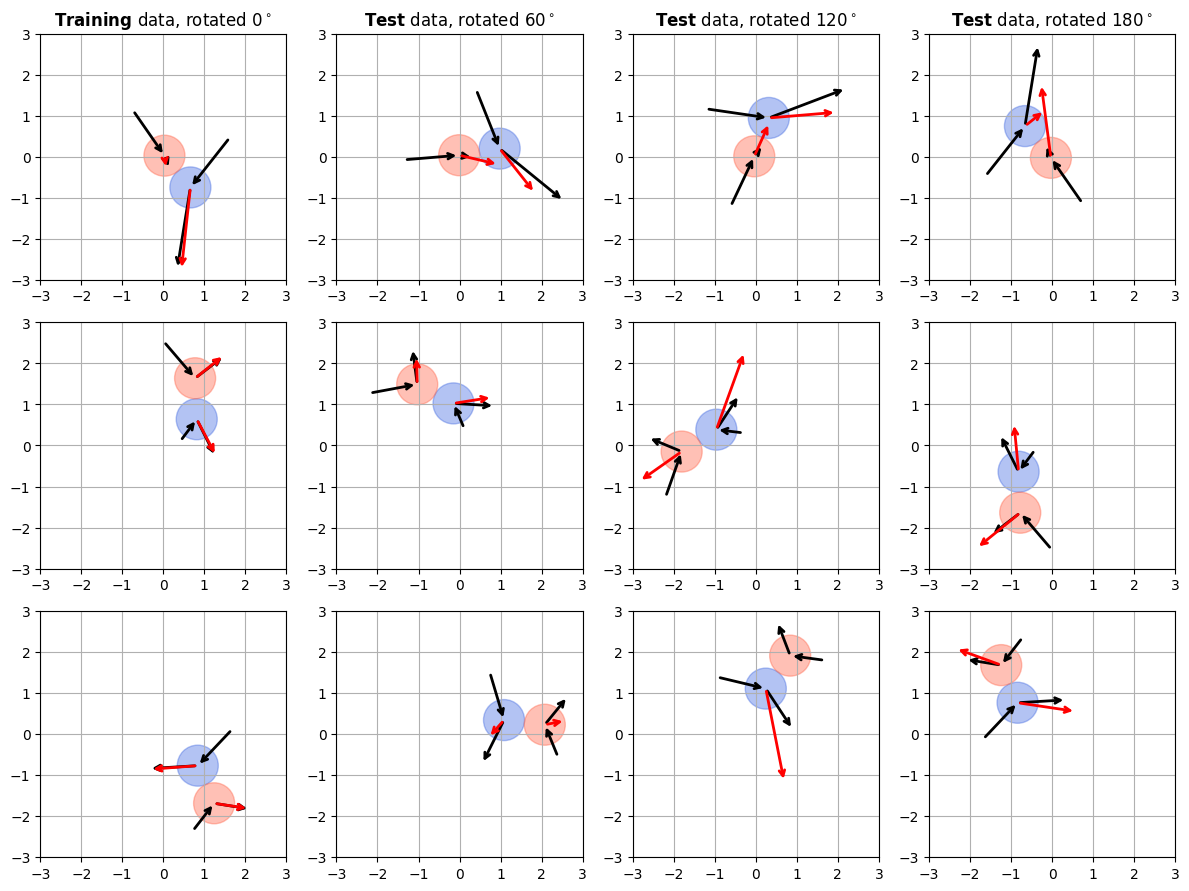

In [53]:
def plot_predictions(model, X, axes):
	with torch.no_grad():
		for i, row in enumerate(axes):
			X_rot = X.clone()
			for j, ax in enumerate(row):
				if j > 0:
					X_rot[:, 0:2] = X_rot[:, 0:2] @ R.T
					X_rot[:, 2:4] = X_rot[:, 2:4] @ R.T
					X_rot[:, 4:6] = X_rot[:, 4:6] @ R.T
					X_rot[:, 6:8] = X_rot[:, 6:8] @ R.T

				y_pred = model(X_rot)
				p1 = X_rot[i, 0:2].clone().numpy()
				p2 = X_rot[i, 2:4].clone().numpy()
				post1 = y_pred[i, 0:2].clone().numpy()
				post2 = y_pred[i, 2:4].clone().numpy()
				# Outgoing velocities (solid arrows starting at disk centres)
				ax.annotate('', xy=p1 + post1, xytext=p1,
							arrowprops=dict(arrowstyle='->', color='red', linestyle='solid', lw=2))
							# arrowprops=dict(arrowstyle='->', color='blue', lw=2))

				ax.annotate('', xy=p2 + post2, xytext=p2,
							arrowprops=dict(arrowstyle='->', color='red', linestyle='solid', lw=2))
							# arrowprops=dict(arrowstyle='->', color='red', lw=2))

model = NN()
X_small = X[:100]
Y_small = Y[:100]
train(model, X_small, Y_small)


fig, axes = plt.subplots(3, 4, figsize=(12, 9))
plot_data(fig, axes)
plot_predictions(model, X, axes)

Training on all 1000 collisions:

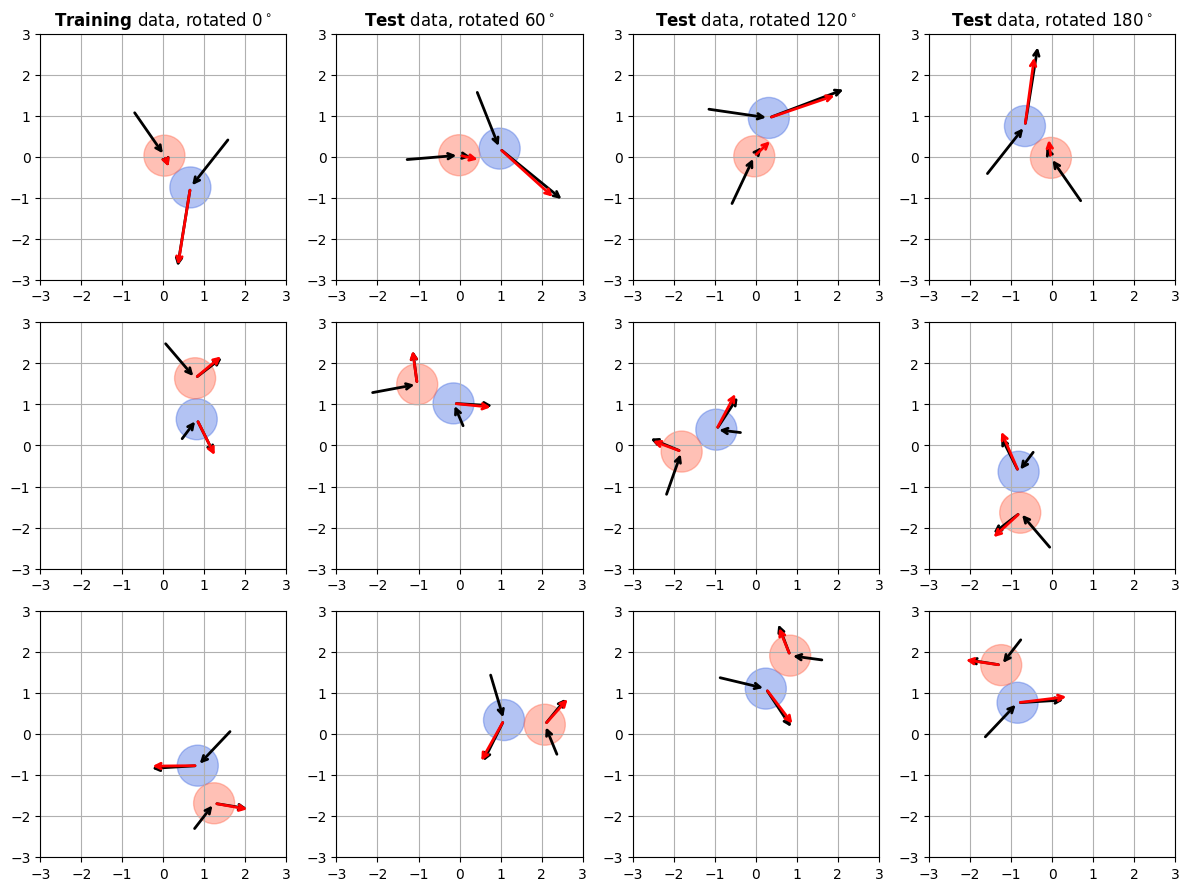

In [54]:
model = NN()
train(model, X, Y)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
plot_data(fig, axes)
plot_predictions(model, X, axes)

### An equivariant neural network

In [64]:
class EquivariantNN(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.net = torch.nn.Sequential(
			torch.nn.Linear(10, 64),
			torch.nn.SiLU(),
			torch.nn.Linear(64, 64),
			torch.nn.SiLU(),
			torch.nn.Linear(64, 8),
		)

	def forward(self, x):
		return self.net(x)

def get_features(X):
	u1 = X[:, 0:2]; u2 = X[:, 2:4]
	u3 = X[:, 4:6]; u4 = X[:, 6:8]
	fX = torch.stack([(u1*u1).sum(dim=1), 
					(u2*u2).sum(dim=1), 
					(u3*u3).sum(dim=1), 
					(u4*u4).sum(dim=1),
					(u1*u2).sum(dim=1),
					(u3*u4).sum(dim=1),
					(u1*u3).sum(dim=1),
					(u2*u4).sum(dim=1),
					(u1*u4).sum(dim=1),
					(u2*u3).sum(dim=1)], dim=1)
	return fX

def predict(model, X):
	u1 = X[:, 0:2]
	u2 = X[:, 2:4]
	u3 = X[:, 4:6]
	u4 = X[:, 6:8]

	fX = get_features(X)
	coeffs = model(fX)
	a = coeffs[:, 0:4]; b = coeffs[:, 4:8]
	w1_pred = a[:, 0].view(-1,1)*u1 + a[:, 1].unsqueeze(-1)*u2 + a[:, 2:3]*u3 + a[:, 3:4]*u4
	w2_pred = b[:, 0:1]*u1 + b[:, 1:2]*u2 + b[:, 2:3]*u3 + b[:, 3:4]*u4
	y_pred = torch.cat([w1_pred, w2_pred], dim=1)
	return y_pred

def train(model, x_train, y_train, lr=0.001, epochs=1000):
	'''Trains a model using "Adam".'''
	optimizer = torch.optim.Adam(model.parameters(), lr=lr)

	for epoch in range(epochs):
		y_pred = predict(model, x_train)
		loss = torch.mean((y_pred-y_train)**2)
		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

Training on JUST 100 data points but using equivariant NN.

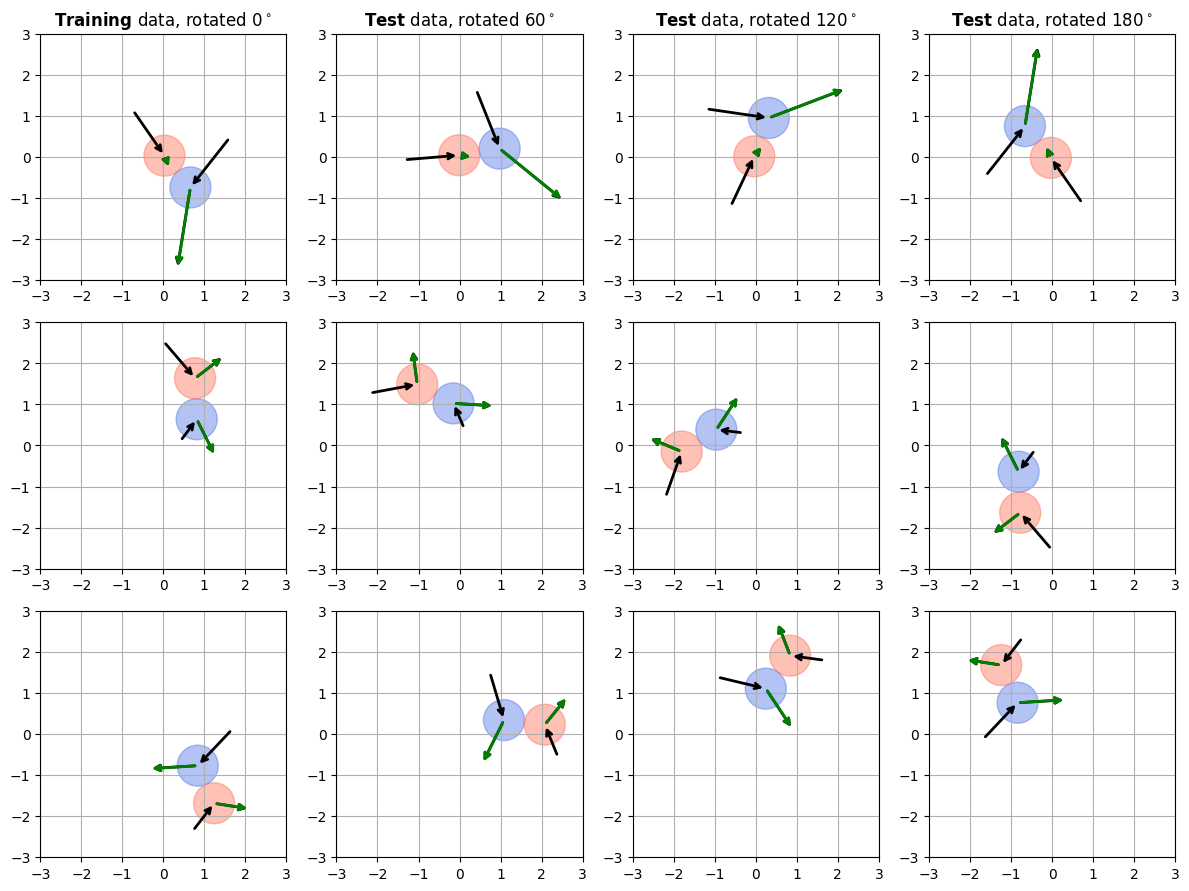

In [65]:
model = EquivariantNN()
train(model, X[:100], Y[:100])

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
plot_data(fig, axes)

with torch.no_grad():
	for i, row in enumerate(axes):
		X_rot = X.clone()
		for j, ax in enumerate(row):
			if j > 0:
				X_rot[:, 0:2] = X_rot[:, 0:2] @ R.T
				X_rot[:, 2:4] = X_rot[:, 2:4] @ R.T
				X_rot[:, 4:6] = X_rot[:, 4:6] @ R.T
				X_rot[:, 6:8] = X_rot[:, 6:8] @ R.T

			y_pred = predict(model, X_rot)
			p1 = X_rot[i, 0:2].clone().numpy()
			p2 = X_rot[i, 2:4].clone().numpy()
			post1 = y_pred[i, 0:2].clone().numpy()
			post2 = y_pred[i, 2:4].clone().numpy()
			# Outgoing velocities (solid arrows starting at disk centres)
			ax.annotate('', xy=p1 + post1, xytext=p1,
						arrowprops=dict(arrowstyle='->', color='green', linestyle='solid', lw=2))
						# arrowprops=dict(arrowstyle='->', color='blue', lw=2))

			ax.annotate('', xy=p2 + post2, xytext=p2,
						arrowprops=dict(arrowstyle='->', color='green', linestyle='solid', lw=2))
						# arrowprops=dict(arrowstyle='->', color='red', lw=2))

# Extra stufffff

In [ ]:
class EquivariantNN(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.net = torch.nn.Sequential(
			torch.nn.Linear(10, 64), 
			torch.nn.SiLU(),
			torch.nn.Linear(64, 64),
			torch.nn.SiLU(),
			torch.nn.Linear(64, 4),
		)

	def forward(self, x):
		return self.net(x)

def get_features(X):
	u1 = X[:, 0:2]; u2 = X[:, 2:4]
	u3 = X[:, 4:6]; u4 = X[:, 6:8]
	fX = torch.stack([(u1*u1).sum(dim=1), 
					(u2*u2).sum(dim=1), 
					(u3*u3).sum(dim=1), 
					(u4*u4).sum(dim=1),
					(u1*u2).sum(dim=1),
					(u3*u4).sum(dim=1),
					(u1*u3).sum(dim=1),
					(u2*u4).sum(dim=1),
					(u1*u4).sum(dim=1),
					(u2*u3).sum(dim=1)], dim=1)
	return fX

def predict(model, X):
	u1 = X[:, 0:2]
	u2 = X[:, 2:4]
	u3 = X[:, 4:6]
	u4 = X[:, 6:8]

	fX = get_features(X)
	coeffs = model(fX)
	w1_pred = coeffs[:, 0:2]; w2_pred = coeffs[:, 2:4]
	# w1_pred = a[:, 0].view(-1,1)*u1 + a[:, 1].unsqueeze(-1)*u2 + a[:, 2:3]*u3 + a[:, 3:4]*u4
	# w2_pred = b[:, 0:1]*u1 + b[:, 1:2]*u2 + b[:, 2:3]*u3 + b[:, 3:4]*u4
	y_pred = torch.cat([w1_pred, w2_pred], dim=1)
	return y_pred

def train(model, x_train, y_train, lr=0.001, epochs=1000):
	'''Trains a model using "Adam".'''
	optimizer = torch.optim.Adam(model.parameters(), lr=lr)

	for epoch in range(epochs):
		y_pred = predict(model, x_train)
		loss = torch.mean((y_pred-y_train)**2)
		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

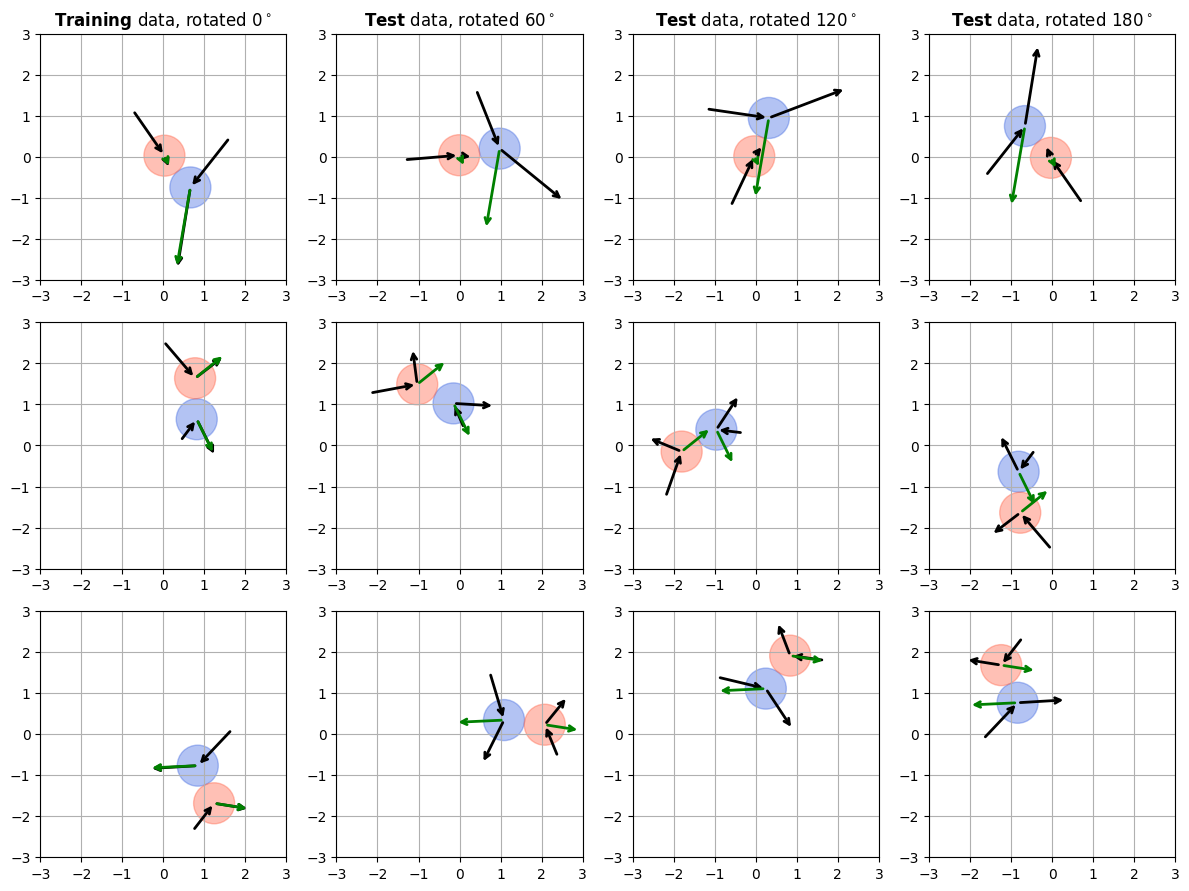

In [69]:
model = EquivariantNN()
train(model, X[:100], Y[:100])

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
plot_data(fig, axes)

with torch.no_grad():
	for i, row in enumerate(axes):
		X_rot = X.clone()
		for j, ax in enumerate(row):
			if j > 0:
				X_rot[:, 0:2] = X_rot[:, 0:2] @ R.T
				X_rot[:, 2:4] = X_rot[:, 2:4] @ R.T
				X_rot[:, 4:6] = X_rot[:, 4:6] @ R.T
				X_rot[:, 6:8] = X_rot[:, 6:8] @ R.T

			y_pred = predict(model, X_rot)
			p1 = X_rot[i, 0:2].clone().numpy()
			p2 = X_rot[i, 2:4].clone().numpy()
			post1 = y_pred[i, 0:2].clone().numpy()
			post2 = y_pred[i, 2:4].clone().numpy()
			# Outgoing velocities (solid arrows starting at disk centres)
			ax.annotate('', xy=p1 + post1, xytext=p1,
						arrowprops=dict(arrowstyle='->', color='green', linestyle='solid', lw=2))
						# arrowprops=dict(arrowstyle='->', color='blue', lw=2))

			ax.annotate('', xy=p2 + post2, xytext=p2,
						arrowprops=dict(arrowstyle='->', color='green', linestyle='solid', lw=2))
						# arrowprops=dict(arrowstyle='->', color='red', lw=2))

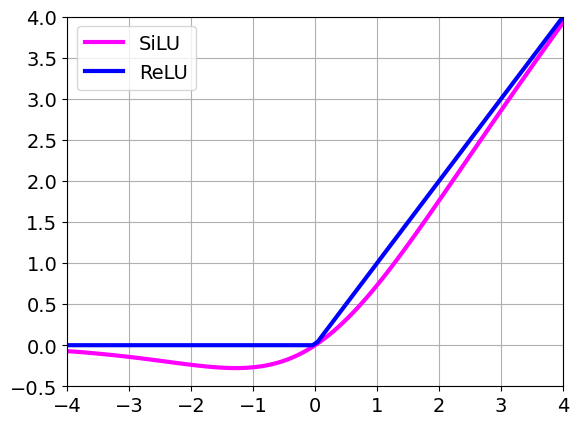

In [26]:
import torch
import matplotlib.pyplot as plt

xs = torch.linspace(-4,4,100)
silu = torch.nn.SiLU()
ys_silu = silu(xs)
relu = torch.nn.ReLU()
ys_relu = relu(xs)

fig, ax = plt.subplots()
ax.plot(xs, ys_silu, label='SiLU', lw=3, color='magenta')
ax.plot(xs, ys_relu, label='ReLU', lw=3, color='blue')
ax.grid()
ax.set_xlim(-4,4)
ax.set_ylim(-0.5, 4)
ax.tick_params(labelsize=14)
ax.legend(fontsize=14)